# Manuscript:   A reference map of CDK-cyclin dependencies across human cancers
# Project:      Codependencies
# Part:         F. TCGA validation
# Author:       Agustín Sánchez-Belmonte
# Date:         04/09/23
# Last update:  08/02/26

# Combined RNAseq in TCGA

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

import gseapy as gspy
from bioinfokit import analys, visuz

from matplotlib import rcParams

In [2]:
sc.set_figure_params(dpi=300, color_map='viridis', figsize =(20, 20))
sc.settings.verbosity = 3
sc.logging.print_header()
rcParams['figure.figsize'] = 10, 10

pal1 = ["lightblue", "deepskyblue", "dodgerblue", "navajowhite", "darkorange", "orangered"]

sc.set_figure_params(dpi_save=300)

scanpy==1.8.2 anndata==0.7.8 umap==0.5.2 numpy==1.21.5 scipy==1.8.0 pandas==1.4.1 scikit-learn==1.0.2 statsmodels==0.13.2 python-igraph==0.9.9 pynndescent==0.5.6


In [4]:
DATA = '/Users/asanchezb/Desktop/MMM/TCGA/data/'
DESKTOP = '/Users/asanchezb/Desktop/'
PATH    = '/Volumes/LaCie/TCGA_ASB/Others/'
sc.settings.figdir = DESKTOP

# 1. LOAD DATA

## Load anndata file (h5ad)

In [ ]:
adata = sc.read(DATA +"TCGA_RNAseq.h5ad")

# 2. PANCANCER

normalizing counts per cell
    finished (0:00:02)


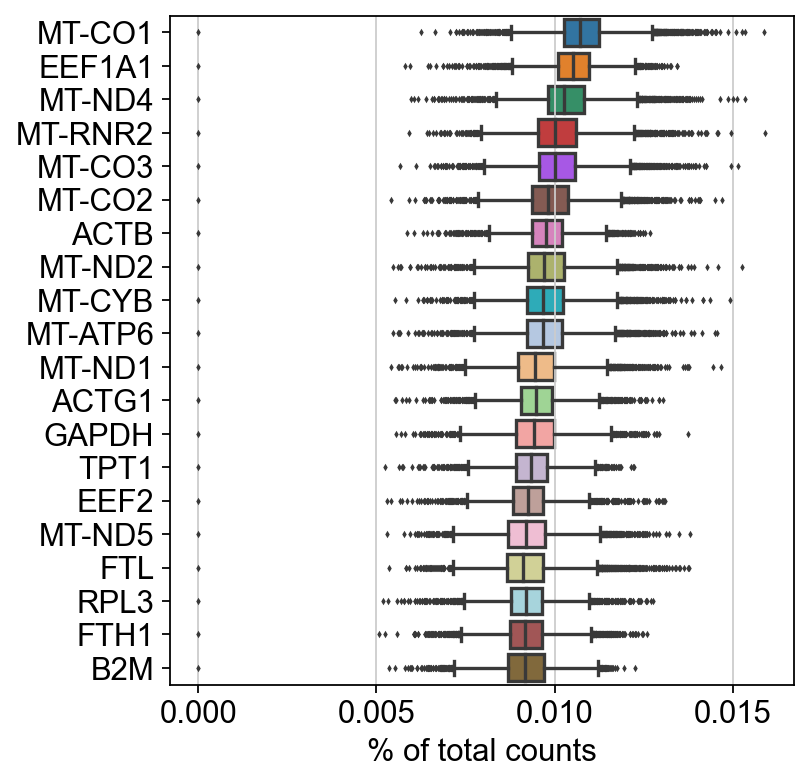

In [6]:
sc.pl.highest_expr_genes(adata, n_top=20)  

## MITOCHONDRIAL GENES

In [7]:
# Search mitochondrial genes and annotate the group of mitochondrial genes as 'MT'
adata.var['MT'] = adata.var_names.str.startswith('MT-')
# Calculate metric
sc.pp.calculate_qc_metrics(adata, qc_vars=['MT'], percent_top=None, log1p=False, inplace=True)

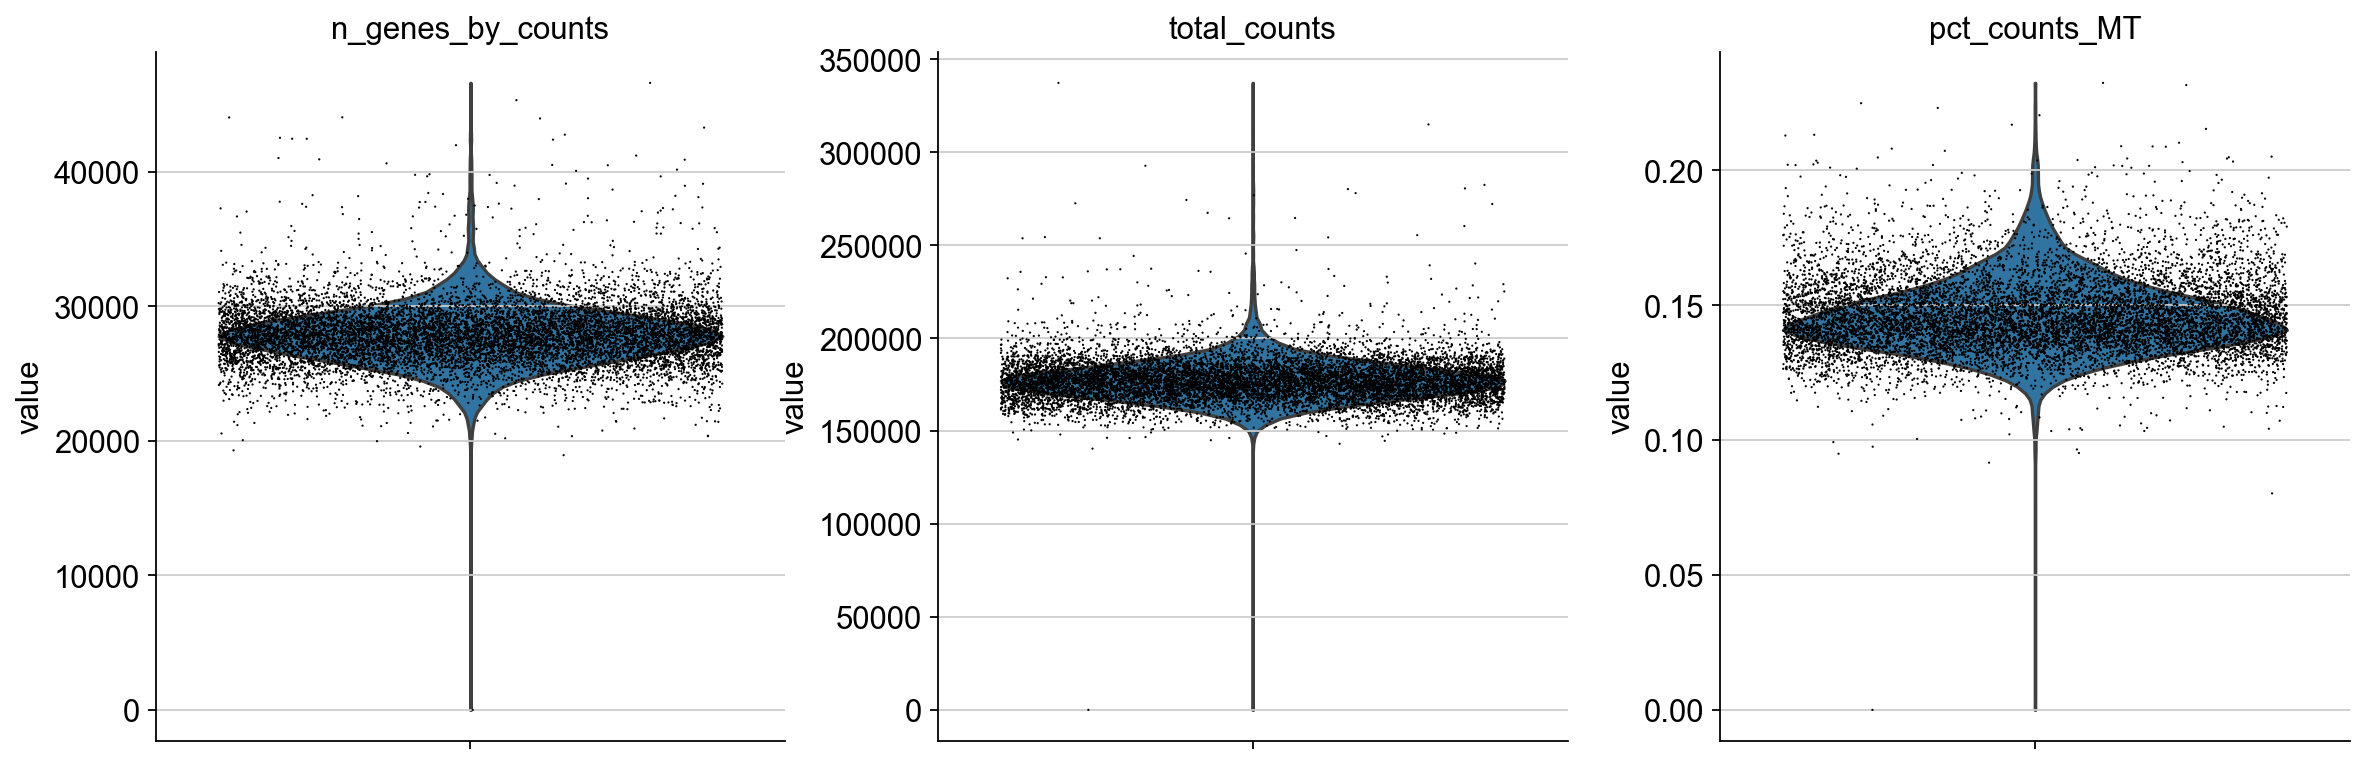

In [8]:
#Plot distribution of mitochondrial genes
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_MT'],
             jitter=0.4, multi_panel=True)

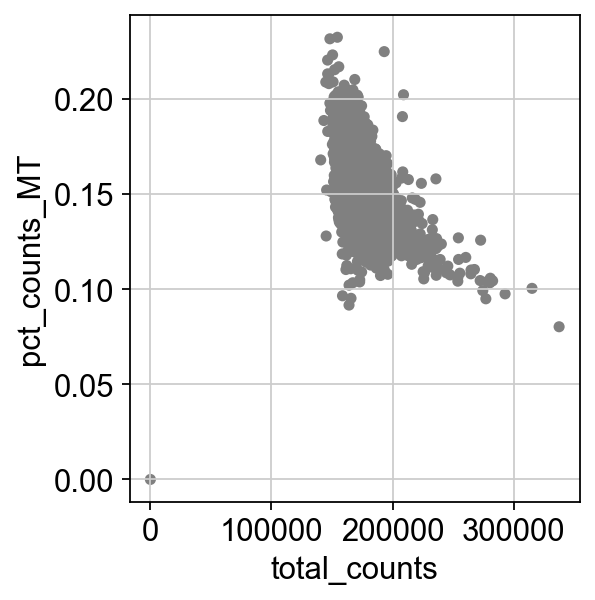

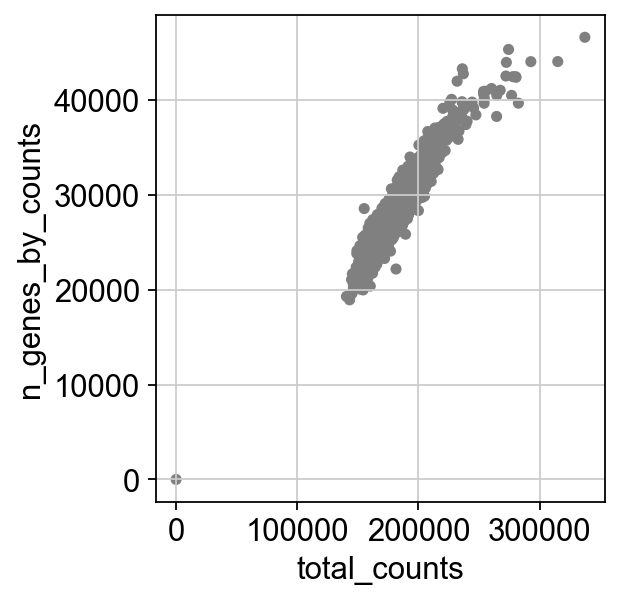

In [9]:
# Plot mitochondrial genes expressed
sc.pl.scatter(adata, x='total_counts', y='pct_counts_MT', size=100)
# Plot total counts
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', size=100)

## NORMALIZE DATA AND LOG

In [10]:
#sc.pp.normalize_total(adata, target_sum=1e5)
#sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=15, min_disp=1)

extracting highly variable genes
    finished (0:00:12)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


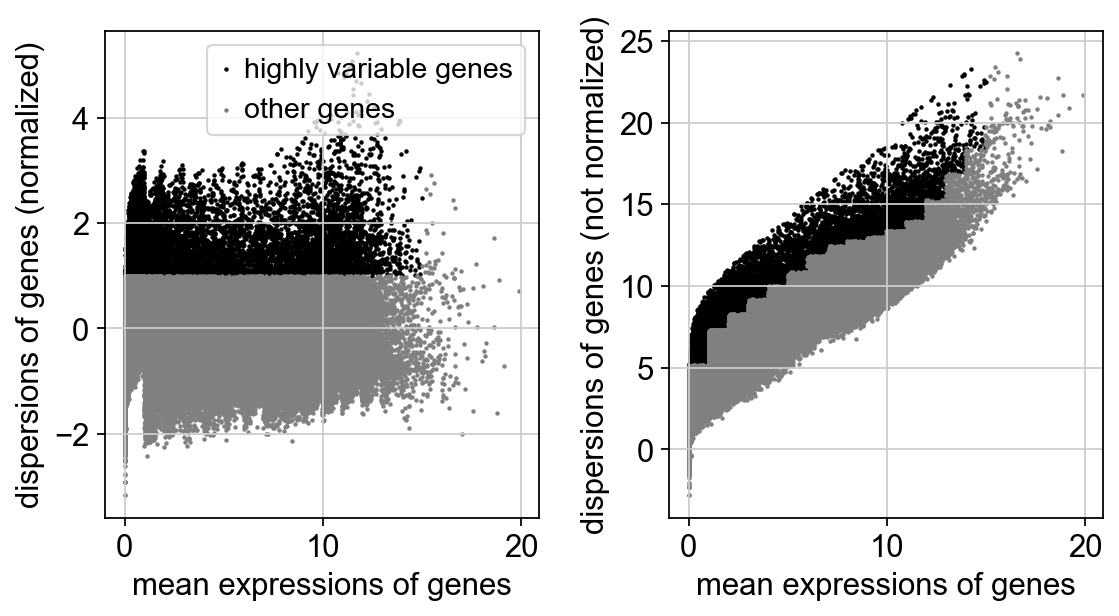

In [11]:
sc.pl.highly_variable_genes(adata) 

## PCA

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:04)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    on highly variable genes
    with n_comps=50
    finished (0:00:03)


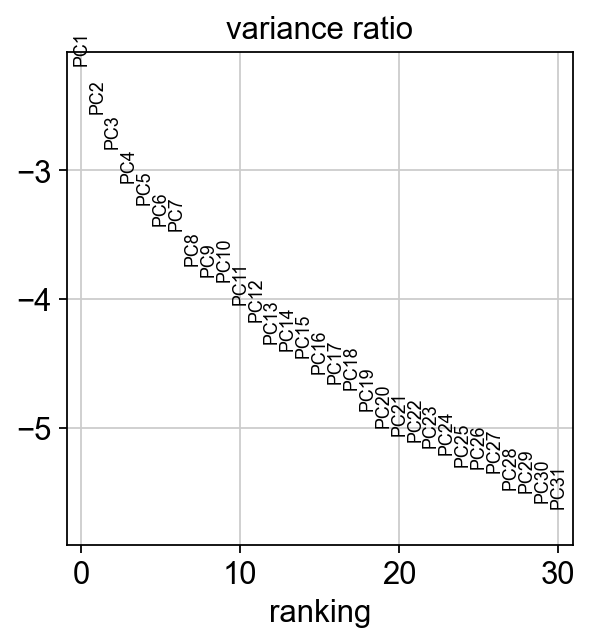

In [102]:
sc.pp.pca(adata)
sc.tl.pca(adata, svd_solver='auto') 
sc.pl.pca_variance_ratio(adata, log=True) 

## UMAP

In [103]:
sc.pp.neighbors(adata, n_neighbors=12, n_pcs=40)
sc.tl.umap(adata)

computing neighbors
    using 'X_pca' with n_pcs = 40
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:11)


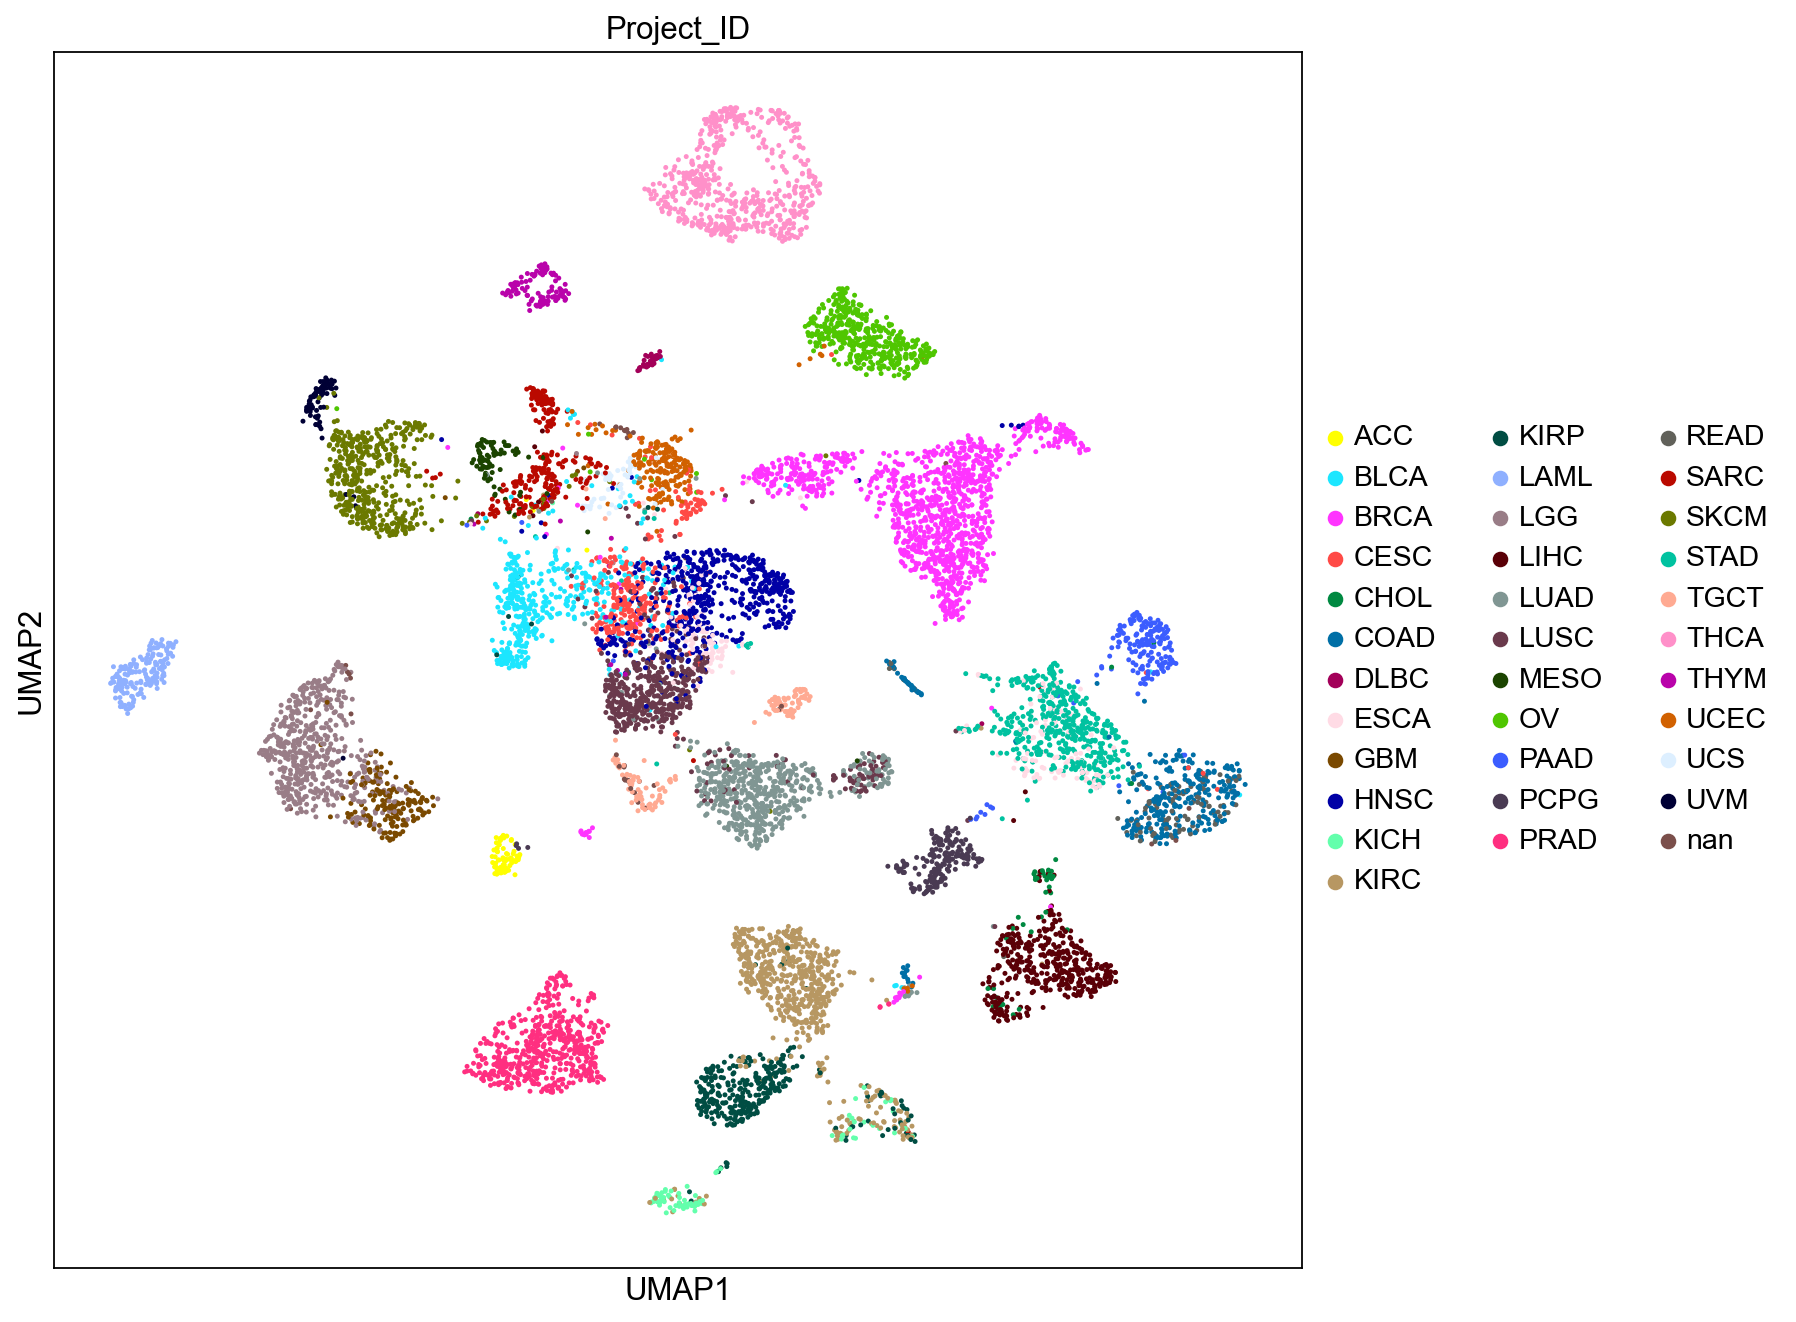

In [36]:
_, ax = plt.subplots(figsize=(10, 10))
sc.pl.umap(adata, color=[ 'Project_ID'], s=20, ax=ax)

### Calculate scores clusters Depmap

In [12]:
# Cargar top markers
marker_table = pd.read_csv("/Users/asanchezb/Desktop/PROJECTS/CODEPENDENCIES_CDKS_CYCLINS/25Q3_RESULTS/top100_markers_per_cluster.tsv", sep="\t", index_col=0)

# Crear diccionario cluster → lista de genes
cluster_genes = {col: marker_table[col].dropna().tolist() for col in marker_table.columns}

In [13]:
cluster_genes

{'A': ['CCND1',
  'ENPP1',
  'PGLYRP2',
  'CTSK',
  'MLPH',
  'TBC1D9',
  'SLC24A3',
  'SELENBP1',
  'METTL1',
  'SELENOP',
  'SCGB1D2',
  'TRPM4',
  'ZNF703',
  'FZD4',
  'HMCN1',
  'TSFM',
  'BAMBI',
  'SCGB2A2',
  'EFHD1',
  'GDF6',
  'PLPPR2',
  'OLFML3',
  'ABCC11',
  'PTGER3',
  'CDK4',
  'SPDEF',
  'CYP4F22',
  'AR',
  'NPTXR',
  'PPP1R1A',
  'TCEA3',
  'TTC39A',
  'SCUBE2',
  'TFF1',
  'IRX5',
  'DIP2C',
  'PHOSPHO1',
  'TRIM3',
  'GHR',
  'HPX',
  'LIPI',
  'NHERF2',
  'CRAT',
  'CORO1B',
  'MARCHF9',
  'NCAM2',
  'LAMB2',
  'DBNDD1',
  'LTO1',
  'PREX1',
  'FGF13',
  'CTTNBP2',
  'RAP1GAP',
  'MUCL1',
  'PIP',
  'PRRT1B',
  'AK1',
  'C2orf72',
  'RBM11',
  'CCK',
  'AMBP',
  'ALDH4A1',
  'ELAPOR1',
  'LMCD1',
  'MAPT',
  'LOXHD1',
  'RAB13',
  'TNS2',
  'ARX',
  'UBL3',
  'F7',
  'EEF1AKMT3',
  'MEGF9',
  'FRS2',
  'CLUL1',
  'PIK3R3',
  'IGFBP5',
  'LIN7A',
  'MAGED1',
  'TTC6',
  'MAGED2',
  'RAB3A',
  'SEZ6L2',
  'CCDC149',
  'RGL1',
  'NKX2-2',
  'NPY1R',
  'SMPD1',
  'CE

In [ ]:
from sklearn.preprocessing import StandardScaler
# 1. Calculate scores
for cluster_name, genes in cluster_genes.items():
    # filter
    genes_in_data = [g for g in genes if g in adata.var_names]
    
    if len(genes_in_data) > 0:
        sc.tl.score_genes(adata, gene_list=genes_in_data, score_name=cluster_name)
    else:
        print(f"Advertencia: No se encontraron genes para {cluster_name}")


names_to_extract = [k for k in cluster_genes.keys() if k in adata.obs.columns]
df_scores = adata.obs[names_to_extract].copy()

# 3. Normalize
scaler = StandardScaler()
df_scores_scaled = pd.DataFrame(
    scaler.fit_transform(df_scores),
    index=df_scores.index,
    columns=df_scores.columns
)

# 4. Classify
adata.obs['predicted_cluster'] = df_scores_scaled.idxmax(axis=1)

for col in df_scores_scaled.columns:
    adata.obs[f"{col}_zscore"] = df_scores_scaled[col].values

# --- verify ---
print(adata.obs[['predicted_cluster'] + names_to_extract].head())

computing score 'A'


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):


    finished: added
    'A', score of gene set (adata.obs).
    650 total control genes are used. (0:00:04)
computing score 'B'


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):


    finished: added
    'B', score of gene set (adata.obs).
    550 total control genes are used. (0:00:04)
computing score 'C'


...

    finished: added
    'F4', score of gene set (adata.obs).
    647 total control genes are used. (0:00:03)
computing score 'F5'


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):


    finished: added
    'F5', score of gene set (adata.obs).
    447 total control genes are used. (0:00:03)
computing score 'F6'


/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):


    finished: added
    'F6', score of gene set (adata.obs).
    350 total control genes are used. (0:00:04)
                predicted_cluster         A         B         C         D  \
Sample_ID                                                                   
TCGA-S9-A7J2-01                 D  2.210662 -0.296384  0.628237  2.193007   
TCGA-G3-A3CH-11                 E  3.109047  2.148774  2.588767 -1.473170   
TCGA-EK-A2RE-01                F5  1.128656 -0.101367  4.413159 -0.009674   
TCGA-44-6778-01                 B  1.948360  3.311702  2.200959  0.747179   
TCGA-F4-6854-01                F3  2.374218  1.091021  2.955702 -0.781093   

                        E        F1        F2        F3        F4        F5  \
Sample_ID                                                                     
TCGA-S9-A7J2-01 -0.084977  4.297306  1.317512 -0.340012  2.338184 -3.781012   
TCGA-G3-A3CH-11  2.637312  2.804731  2.644422  1.391907  2.232268  0.292865   
TCGA-EK-A2RE-01 -0.759011  3.954302

In [107]:
adata.obs['predicted_cluster'].value_counts()

A     2018
D     1686
F5    1117
B      992
E      836
F4     793
F6     742
F2     651
C      603
F3     596
F1     501
Name: predicted_cluster, dtype: int64

/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'predicted_cluster' as categorical


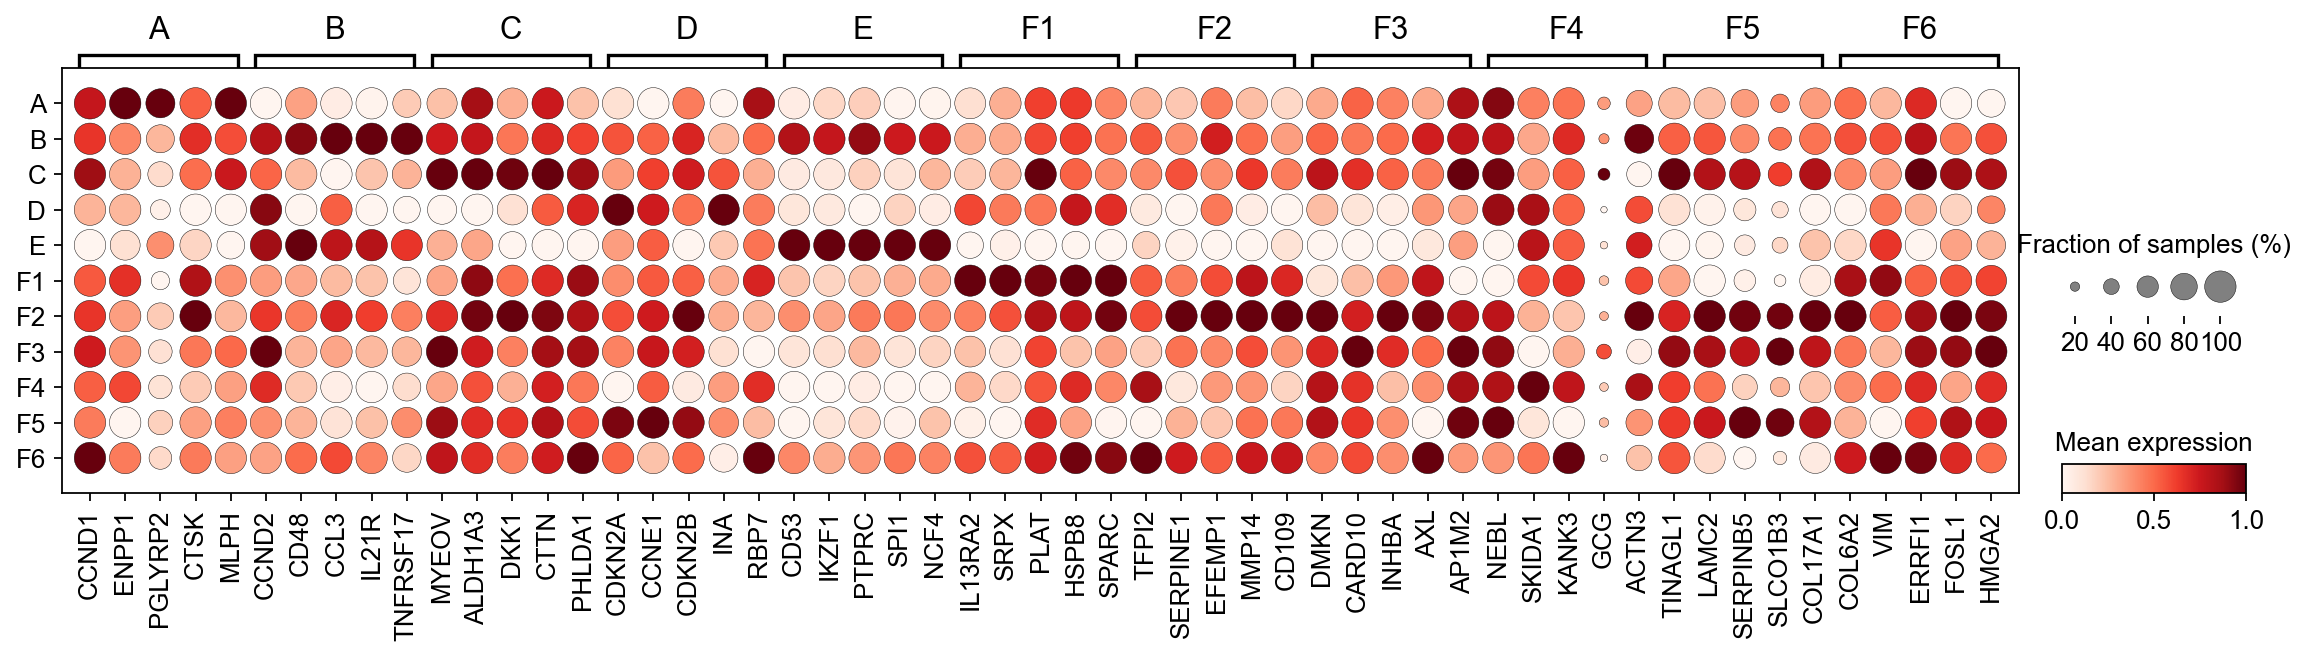

In [ ]:

cluster_genes_top5_unique = {}
seen_genes = set()  # 

for cluster, genes in cluster_genes.items():
    valid_genes = []
    for g in genes:
        
        if g in adata.var_names and g not in seen_genes:
            valid_genes.append(g)
            seen_genes.add(g)
        
        if len(valid_genes) == 5:
            break
            
    cluster_genes_top5_unique[cluster] = valid_genes


manual_figsize = (17.5, 3.5) 

try:
    sc.pl.dotplot(
        adata, 
        var_names=cluster_genes_top5_unique, 
        groupby='predicted_cluster', 
        standard_scale='var', 
        cmap='Reds',
        figsize=manual_figsize,
        colorbar_title='Mean expression',
        size_title='Fraction of samples (%)',
        expression_cutoff=0.05, 
        show=True, save='test.png'
    )
except ValueError as e:
    print(f"Error persistente: {e}")
    print("Categorías detectadas:", adata.obs['predicted_cluster'].unique())

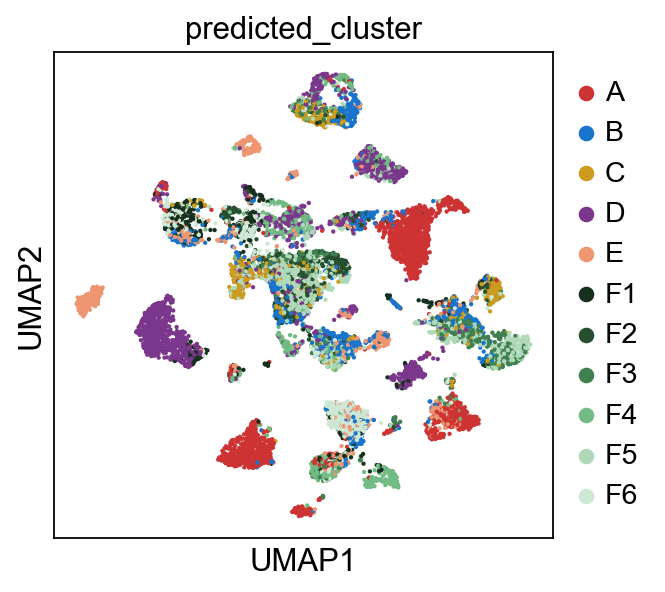

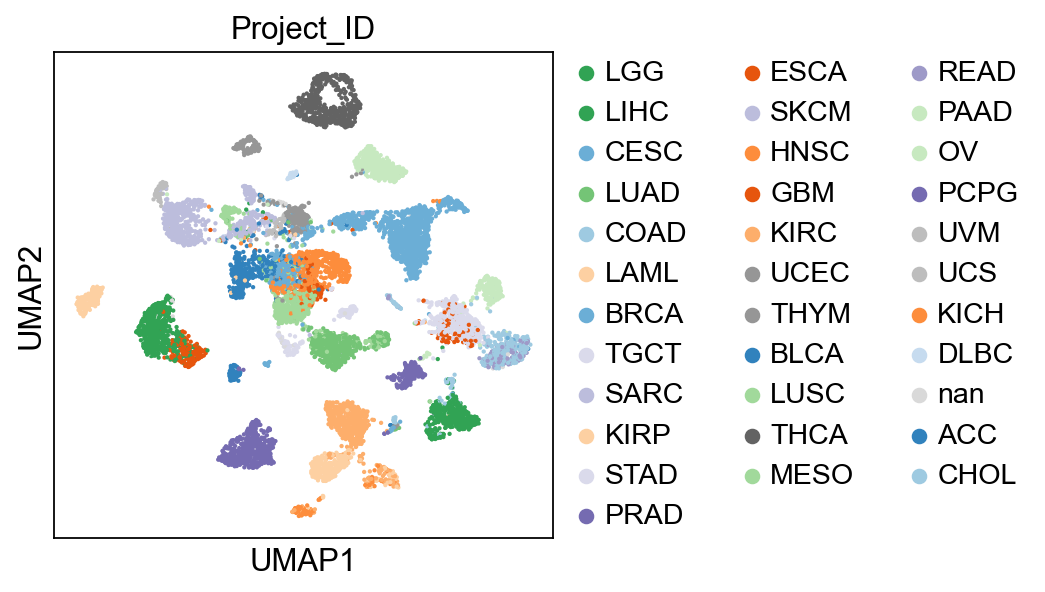

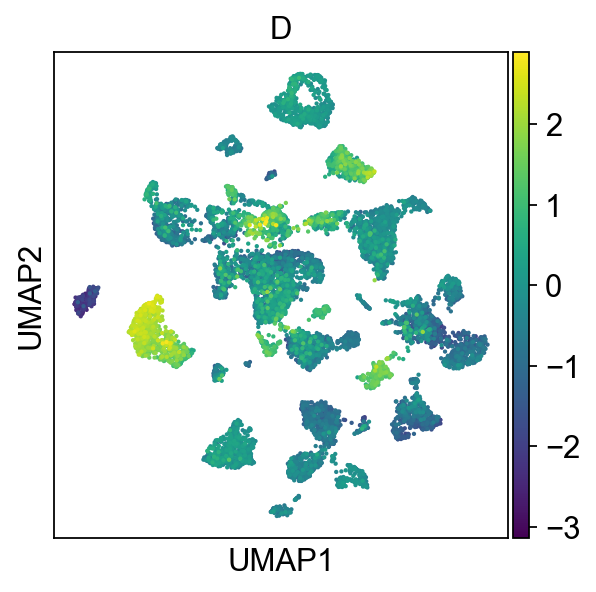

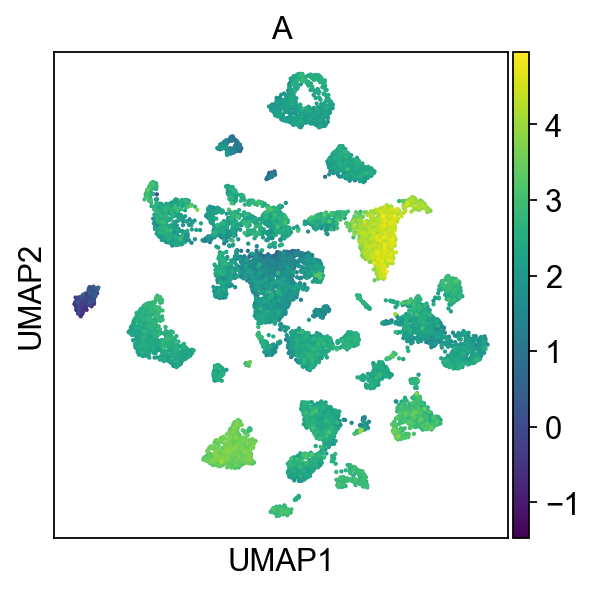

In [91]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
# --- 2️⃣ Definir colores para los Project_IDs ---

# --- 1️⃣ Crear tabla de conteos (NO proporciones) ---

cluster_colors = {
    "A"  : "#CD3333",
    "B"  : "#1874CD",
    "C"  : "#CD9B1D",
    "D"  : "#7A378B",
    "E"  : "#EE9572",
    "F1" : "#17301D",
    "F2" : "#264F30",
    "F3" : "#3E804F",
    "F4" : "#72BB84",
    "F5" : "#B0D9BA",
    "F6" : "#CFE8D5"
}

# --- Asegurarse que predicted_cluster sea categorical ---
cluster_order = list(cluster_colors.keys())
adata.obs['predicted_cluster'] = pd.Categorical(
    adata.obs['predicted_cluster'],
    categories=cluster_order,
    ordered=True
)

# --- Asegurarse que Project_ID sea categorical ---
project_order = list(adata.obs['Project_ID'].unique())
adata.obs['Project_ID'] = pd.Categorical(
    adata.obs['Project_ID'],
    categories=project_order,
    ordered=True
)

# --- 1️⃣ UMAP coloreado por predicted_cluster ---
sc.pl.umap(
    adata,
    color='predicted_cluster',
    s=15,
    palette=[cluster_colors.get(c, '#000000') for c in adata.obs['predicted_cluster'].cat.categories],
    save='_predicted_cluster_custom.png'
)

# --- 2️⃣ UMAP coloreado por Project_ID ---
sc.pl.umap(
    adata,
    color='Project_ID',
    s=15,
    palette=[project_colors.get(c, '#000000') for c in adata.obs['Project_ID'].cat.categories],
    save='_Project_ID_custom.png'
)

# --- UMAP coloreado por score D (numérico) ---
sc.pl.umap(
    adata,
    color='D',       # columna numérica
    s=15,
    cmap='viridis',  # colormap continuo, puedes cambiar a 'plasma', 'cividis', etc.
    save='_D_score.png'
)

# --- UMAP coloreado por score D (numérico) ---
sc.pl.umap(
    adata,
    color='A',       # columna numérica
    s=15,
    cmap='viridis',  # colormap continuo, puedes cambiar a 'plasma', 'cividis', etc.
    save='_A_score.png'
)

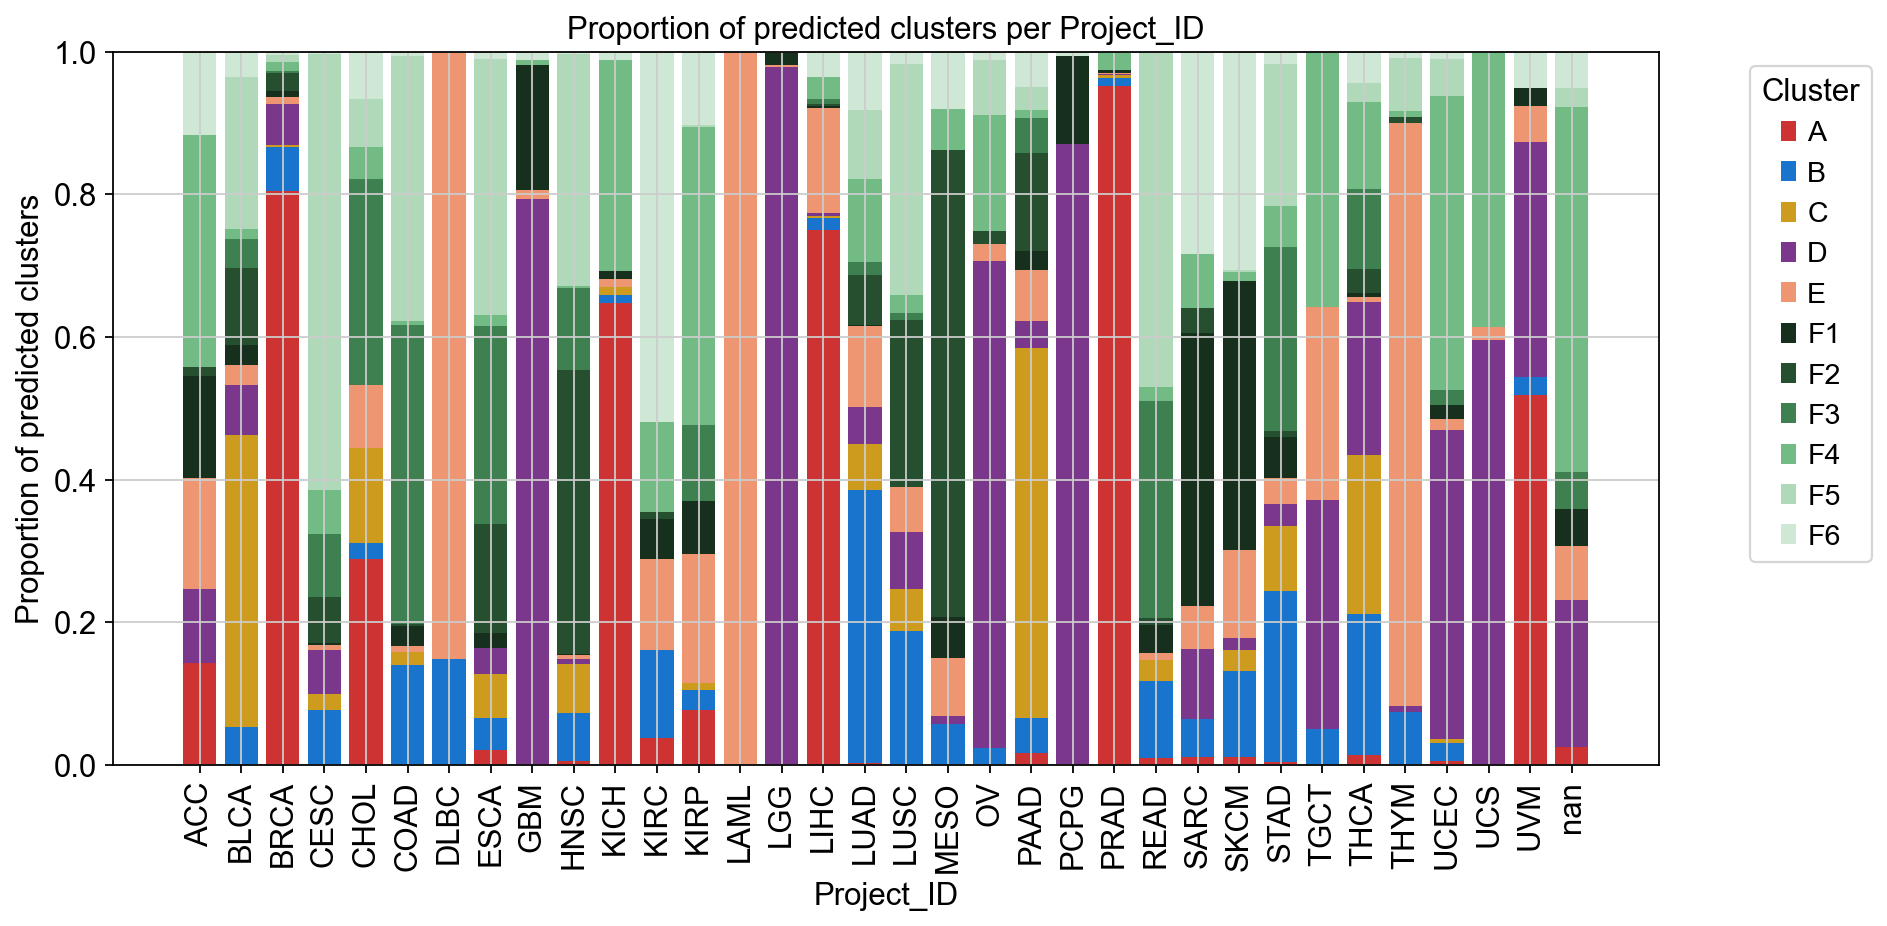

In [108]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1️⃣ Crear tabla de proporciones ---
# adata.obs debe tener: 'predicted_cluster' y 'Project_ID'
prop_table = (
    adata.obs
    .groupby(['Project_ID', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

# Convertir a proporción
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

# --- 2️⃣ Definir colores para clusters ---
cluster_colors = {
    "A"  : "#CD3333",
    "B"  : "#1874CD",
    "C"  : "#CD9B1D",
    "D"  : "#7A378B",
    "E"  : "#EE9572",
    "F1" : "#17301D",
    "F2" : "#264F30",
    "F3" : "#3E804F",
    "F4" : "#72BB84",
    "F5" : "#B0D9BA",
    "F6" : "#CFE8D5"
}

# Ordenar columnas para que coincida con colores
prop_table = prop_table[cluster_colors.keys()]

# --- 3️⃣ Graficar stacked bar ---
fig, ax = plt.subplots(figsize=(12,6))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(x, prop_table[cluster], bottom=bottom, color=cluster_colors[cluster], label=cluster)
    bottom += prop_table[cluster].values

# Etiquetas
ax.set_xticks(x)
ax.set_xticklabels(prop_table.index, rotation=90)
ax.set_ylabel("Proportion of predicted clusters")
ax.set_xlabel("Project_ID")
ax.set_title("Proportion of predicted clusters per Project_ID")
ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_project_per_cluster.png", dpi=300)   # PNG
plt.show()


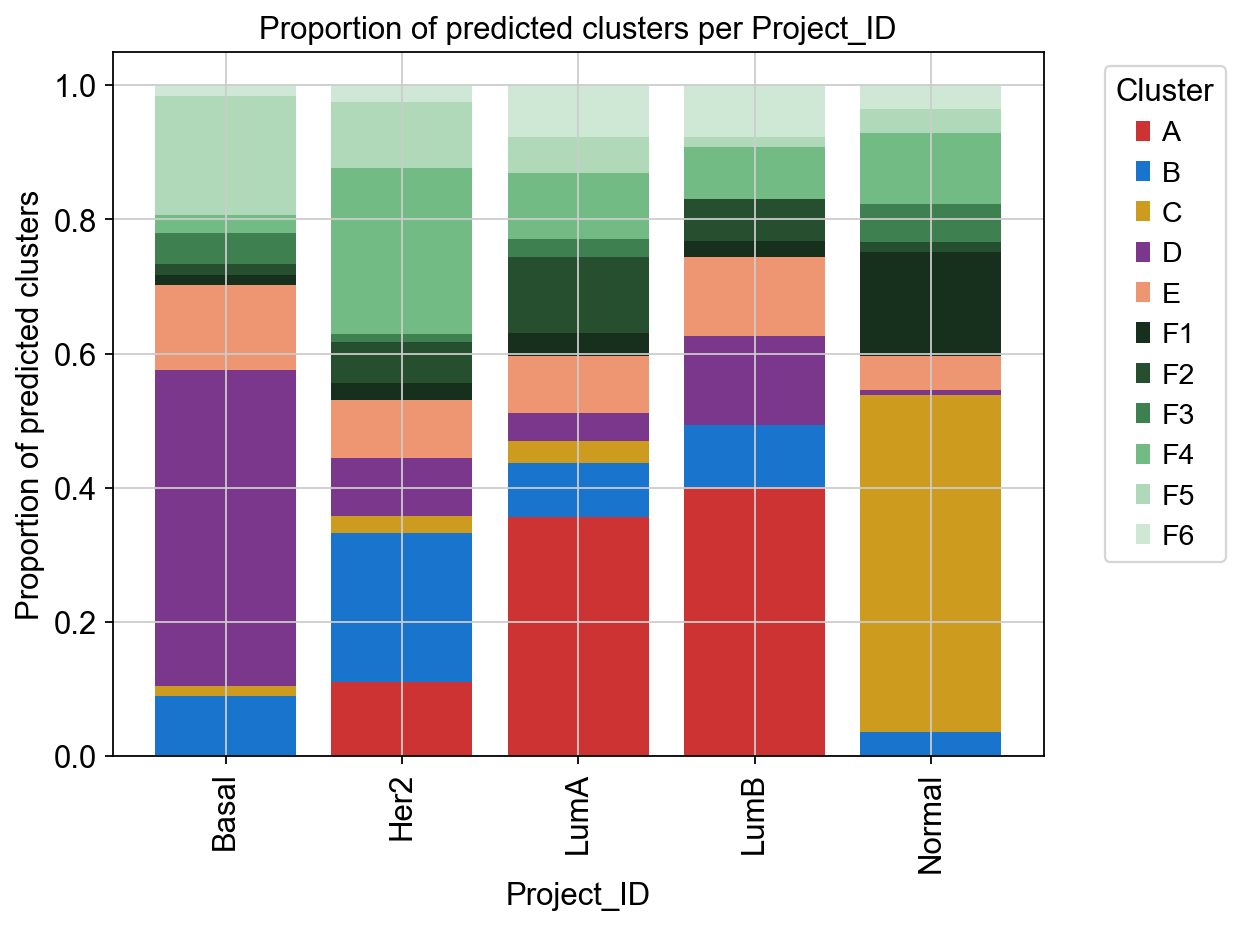

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1️⃣ Crear tabla de proporciones ---
# adata.obs debe tener: 'predicted_cluster' y 'Project_ID'
prop_table = (
    adata.obs
    .groupby(['Subtype_mRNA', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

# Convertir a proporción
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

# --- 2️⃣ Definir colores para clusters ---
cluster_colors = {
    "A"  : "#CD3333",
    "B"  : "#1874CD",
    "C"  : "#CD9B1D",
    "D"  : "#7A378B",
    "E"  : "#EE9572",
    "F1" : "#17301D",
    "F2" : "#264F30",
    "F3" : "#3E804F",
    "F4" : "#72BB84",
    "F5" : "#B0D9BA",
    "F6" : "#CFE8D5"
}

# Ordenar columnas para que coincida con colores
prop_table = prop_table[cluster_colors.keys()]

# --- 3️⃣ Graficar stacked bar ---
fig, ax = plt.subplots(figsize=(8,6))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(x, prop_table[cluster], bottom=bottom, color=cluster_colors[cluster], label=cluster)
    bottom += prop_table[cluster].values

# Etiquetas
ax.set_xticks(x)
ax.set_xticklabels(prop_table.index, rotation=90)
ax.set_ylabel("Proportion of predicted clusters")
ax.set_xlabel("Project_ID")
ax.set_title("Proportion of predicted clusters per Project_ID")
ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_project_per_cluster.png", dpi=300)   # PNG
plt.show()


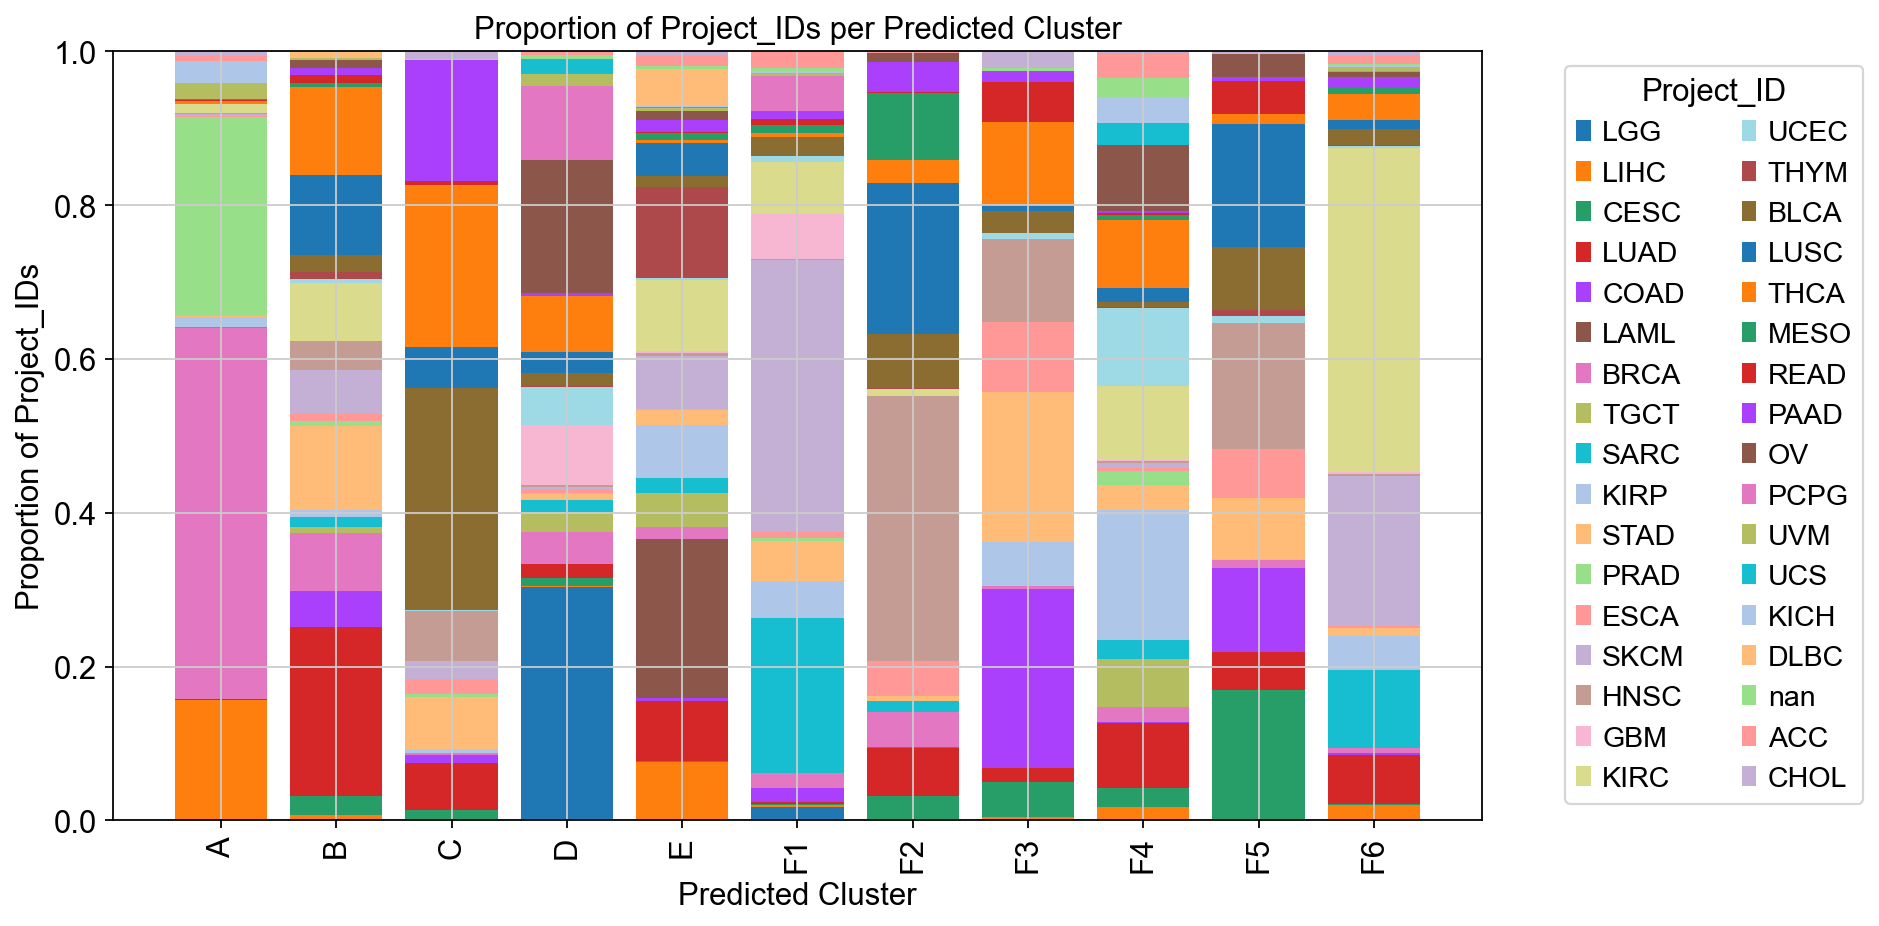

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1️⃣ Crear tabla de proporciones ---
# adata.obs debe tener: 'predicted_cluster' y 'Project_ID'
prop_table = (
    adata.obs
    .groupby(['predicted_cluster', 'Project_ID'])
    .size()
    .unstack(fill_value=0)
)

# Convertir a proporción por cluster (filas suman 1)
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

# --- 2️⃣ Definir colores para los Project_IDs ---
project_ids = count_table.columns
cmap = plt.get_cmap("tab20c")
project_colors = {proj: cmap(i / len(project_ids)) for i, proj in enumerate(project_ids)}

# --- 3️⃣ Graficar stacked bar ---
fig, ax = plt.subplots(figsize=(12,6))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for proj in prop_table.columns:
    ax.bar(x, prop_table[proj], bottom=bottom, label=proj)
    bottom += prop_table[proj].values

# Etiquetas
ax.set_xticks(x)
ax.set_xticklabels(prop_table.index, rotation=90)
ax.set_ylabel("Proportion of Project_IDs")
ax.set_xlabel("Predicted Cluster")
ax.set_title("Proportion of Project_IDs per Predicted Cluster")
ax.legend(
    title="Project_ID",
    bbox_to_anchor=(1.05, 1),  # posición fuera de la figura a la derecha
    loc='upper left',           # punto de anclaje de la leyenda
    ncol=2                      # número de columnas en la leyenda
)

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_project_per_cluster.png", dpi=300)
plt.show()


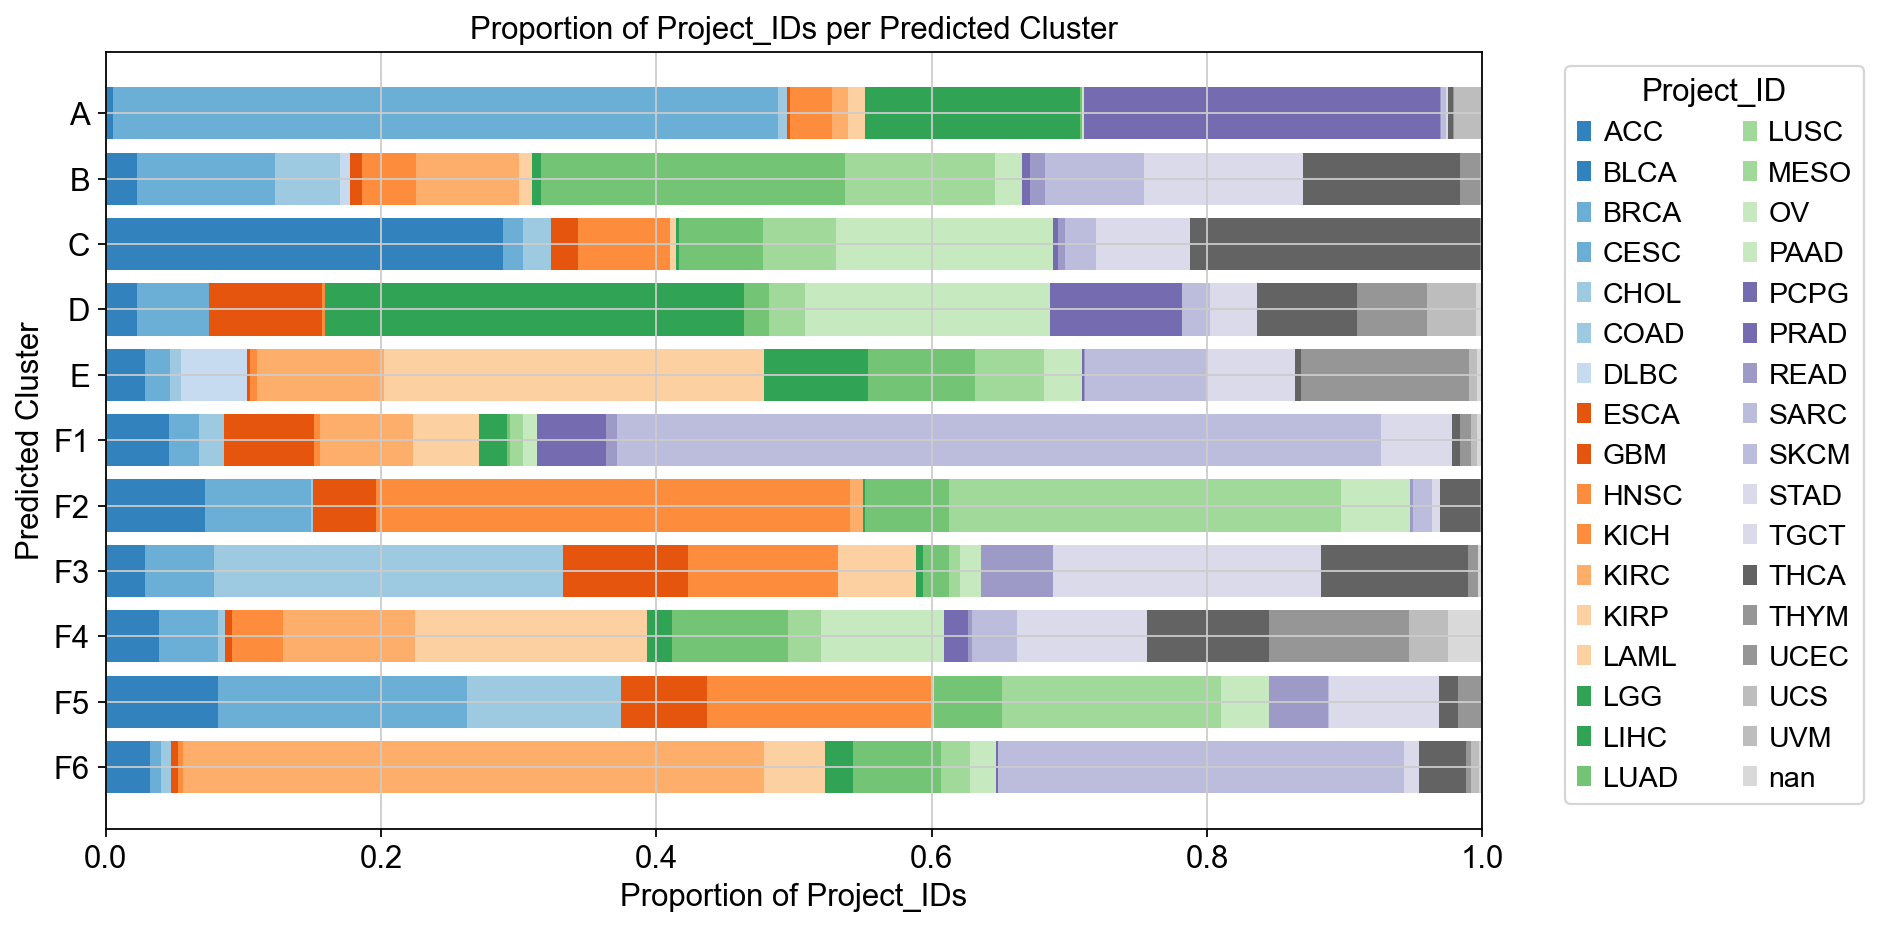

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1️⃣ Crear tabla de proporciones ---
prop_table = (
    adata.obs
    .groupby(['predicted_cluster', 'Project_ID'])
    .size()
    .unstack(fill_value=0)
)

# Convertir a proporción por cluster (filas suman 1)
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

# --- 2️⃣ Colores para Project_IDs usando tab20c interpolado ---
project_ids = prop_table.columns
cmap = plt.get_cmap("tab20c")
project_colors = {proj: cmap(i / len(project_ids)) for i, proj in enumerate(project_ids)}

# --- 2️⃣b Forzar orden de clusters de arriba (A) a abajo (F6) ---
cluster_order = ['A','B','C','D','E','F1','F2','F3','F4','F5','F6']
prop_table = prop_table.reindex(cluster_order)

# --- 3️⃣ Graficar stacked horizontal bar ---
fig, ax = plt.subplots(figsize=(12,6))

left = np.zeros(len(prop_table))
y = np.arange(len(prop_table))

for proj in prop_table.columns:
    ax.barh(
        y,
        prop_table[proj],
        left=left,
        label=proj,
        color=project_colors[proj]
    )
    left += prop_table[proj].values

# --- 4️⃣ Etiquetas ---
ax.set_yticks(y)
ax.set_yticklabels(prop_table.index)
ax.invert_yaxis()  # 🔹 Esto pone A arriba y F6 abajo

ax.set_xlabel("Proportion of Project_IDs")
ax.set_ylabel("Predicted Cluster")
ax.set_title("Proportion of Project_IDs per Predicted Cluster")

ax.legend(
    title="Project_ID",
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    ncol=2
)

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_project_per_cluster_horizontal.png", dpi=300)
plt.show()

In [111]:
# --- Contar N por cluster ---
count_table = (
    adata.obs
    .groupby('predicted_cluster')
    .size()
)

print("Número de samples por cluster:")
print(count_table)

Número de samples por cluster:
predicted_cluster
A     2018
B      992
C      603
D     1686
E      836
F1     501
F2     651
F3     596
F4     793
F5    1117
F6     742
dtype: int64


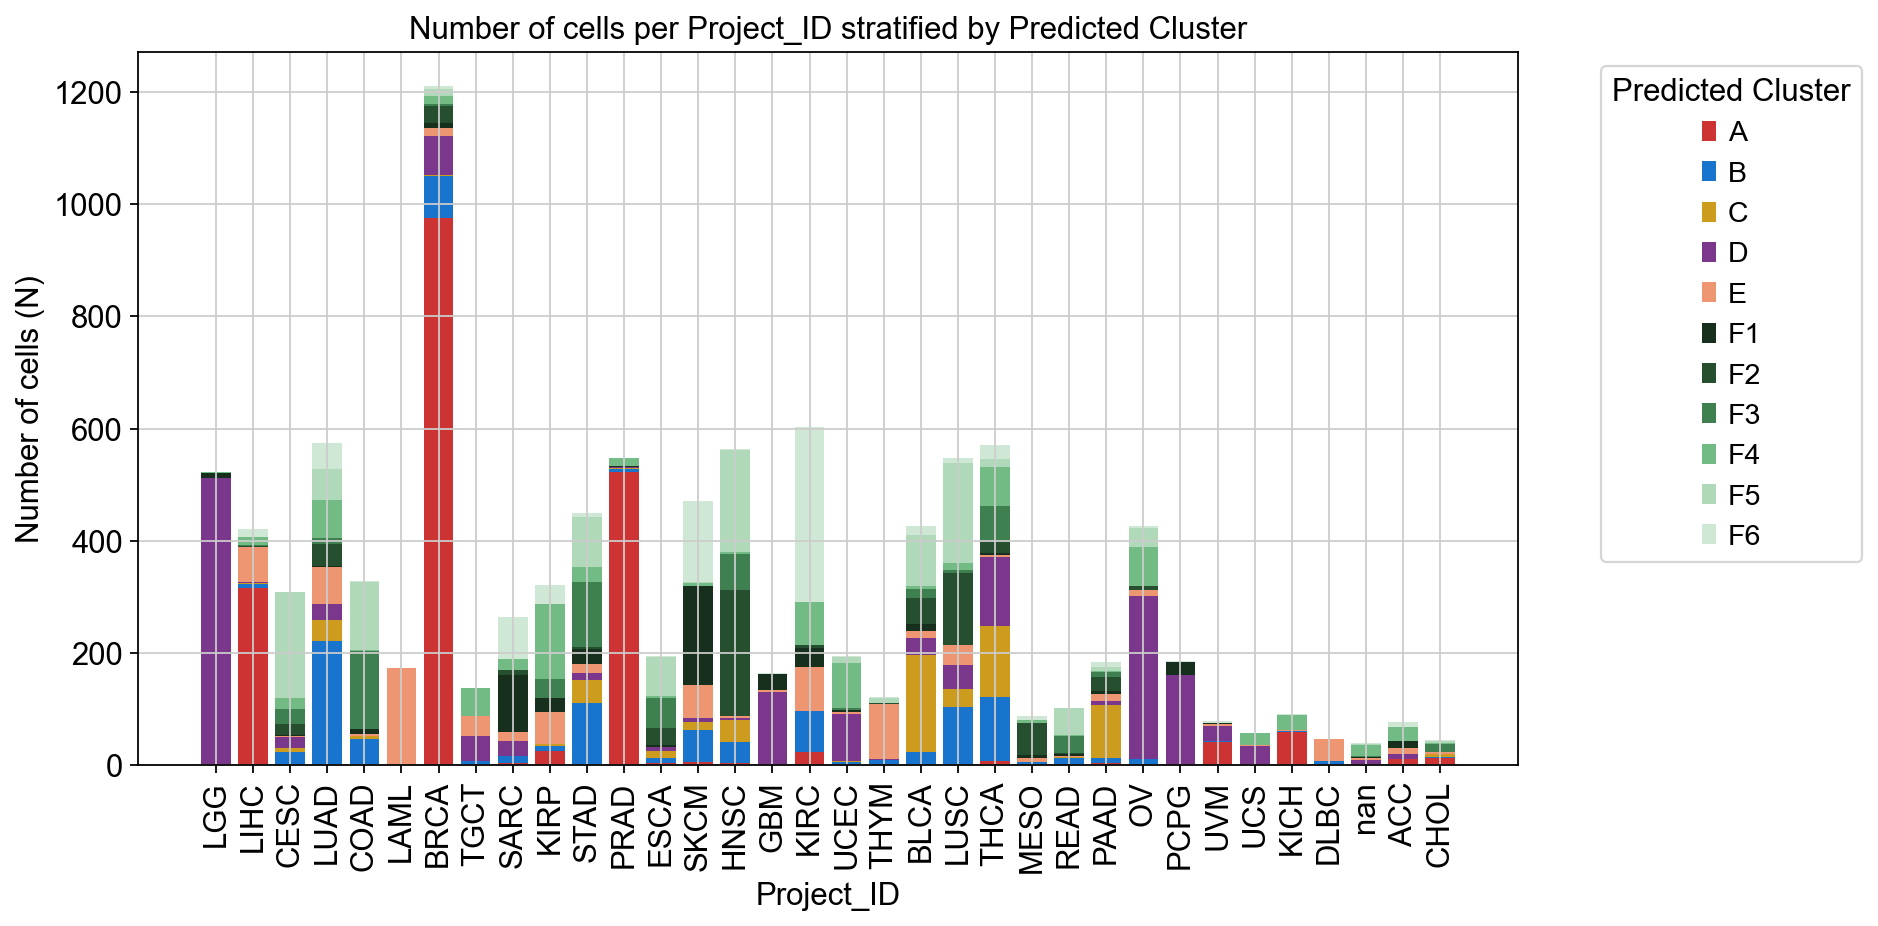

In [59]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1️⃣ Crear tabla de conteos (NO proporciones) ---
count_table = (
    adata.obs
    .groupby(['Project_ID', 'predicted_cluster'])  # invertimos orden
    .size()
    .unstack(fill_value=0)
)

# --- 2️⃣ Colores por cluster (puedes usar tu diccionario si quieres) ---
cluster_colors = {
    "A"  : "#CD3333",
    "B"  : "#1874CD",
    "C"  : "#CD9B1D",
    "D"  : "#7A378B",
    "E"  : "#EE9572",
    "F1" : "#17301D",
    "F2" : "#264F30",
    "F3" : "#3E804F",
    "F4" : "#72BB84",
    "F5" : "#B0D9BA",
    "F6" : "#CFE8D5"
}

# Asegurar orden consistente de clusters
cluster_order = list(cluster_colors.keys())
count_table = count_table[cluster_order]

# --- 3️⃣ Graficar stacked bar ---
fig, ax = plt.subplots(figsize=(12,6))

bottom = np.zeros(len(count_table))
x = np.arange(len(count_table))



for cluster in cluster_order:
    ax.bar(
        x,
        count_table[cluster],
        bottom=bottom,
        label=cluster,
        color=cluster_colors[cluster]
    )
    bottom += count_table[cluster].values

# --- 4️⃣ Etiquetas ---
ax.set_xticks(x)
ax.set_xticklabels(count_table.index, rotation=90)
ax.set_ylabel("Number of cells (N)")
ax.set_xlabel("Project_ID")
ax.set_title("Number of cells per Project_ID stratified by Predicted Cluster")

ax.legend(
    title="Predicted Cluster",
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    ncol=1
)

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_N_project_per_cluster.png", dpi=300)
plt.show()

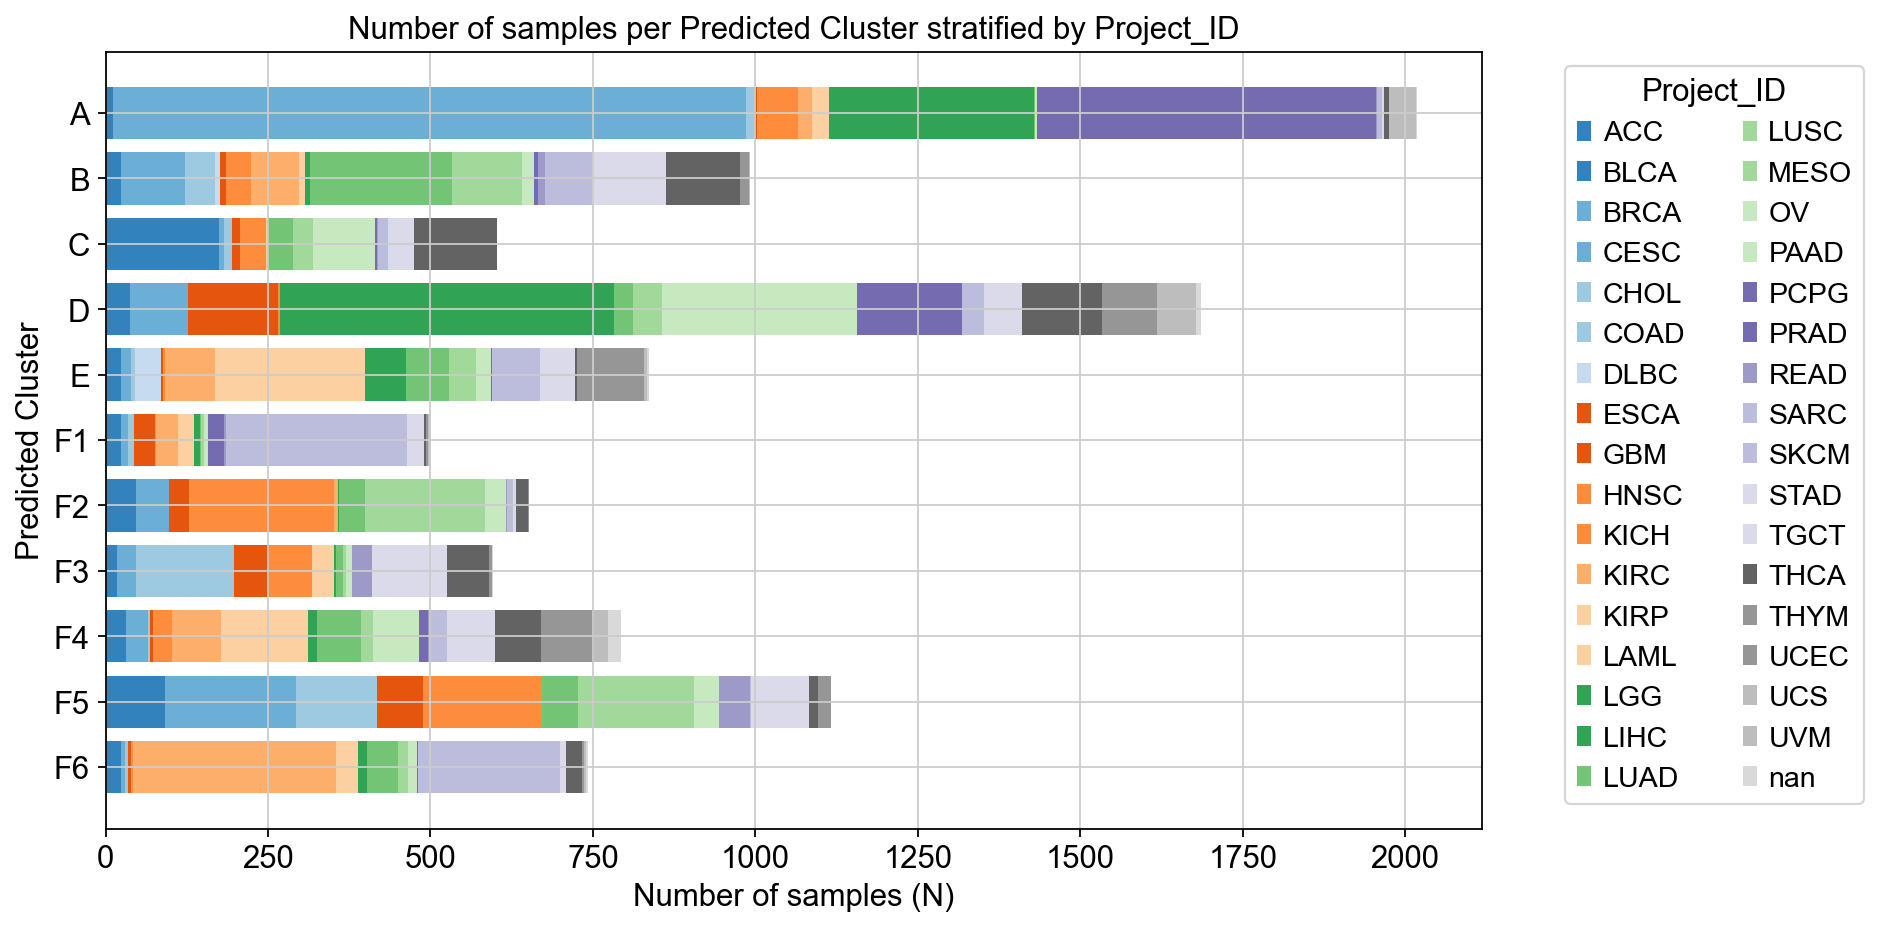

In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1️⃣ Crear tabla de CONTEOS (NO proporciones) ---
count_table = (
    adata.obs
    .groupby(['predicted_cluster', 'Project_ID'])
    .size()
    .unstack(fill_value=0)
)

# --- 2️⃣ Definir colores para los Project_IDs ---
project_ids = count_table.columns
cmap = plt.get_cmap("tab20c")
project_colors = {proj: cmap(i / len(project_ids)) for i, proj in enumerate(project_ids)}

# --- 2️⃣b Forzar orden de clusters A → F6 ---
cluster_order = ['A','B','C','D','E','F1','F2','F3','F4','F5','F6']
count_table = count_table.reindex(cluster_order)

# --- 3️⃣ Graficar stacked horizontal bar ---
fig, ax = plt.subplots(figsize=(12,6))

left = np.zeros(len(count_table))
y = np.arange(len(count_table))

for proj in count_table.columns:
    ax.barh(
        y,
        count_table[proj],
        left=left,
        label=proj,
        color=project_colors[proj]
    )
    left += count_table[proj].values

# --- 4️⃣ Etiquetas ---
ax.set_yticks(y)
ax.set_yticklabels(count_table.index)
ax.invert_yaxis()  # 🔹 A arriba, F6 abajo

ax.set_xlabel("Number of samples (N)")
ax.set_ylabel("Predicted Cluster")
ax.set_title("Number of samples per Predicted Cluster stratified by Project_ID")

ax.legend(
    title="Project_ID",
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    ncol=2
)

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_N_project_per_cluster_horizontal.png", dpi=300)
plt.show()

In [114]:
cdks = ['CDK1', 'CDK2', 'CDK3', 'CDK4', 'CDK5', 'CDK6', 'CDK7', 'CDK8', 'CDK9', 'CDK10', 
        'CDK11A', 'CDK11B', 'CDK12', 'CDK14', 'CDK15', 'CDK16', 'CDK17', 'CDK18',        #'CDK13', 
        'CDK19', 'CDK20']

In [115]:
cyclins = ['CCND1', 'CCND2', 'CCND3', 'CCNC', 'CCNE1', 'CCNE2', 'CCNF', 'CCNA2', 'CCNB1', 'CCNB2', 
           'CCNB3', 'CCNG1', 'CCNG2', 'CCNH', 'CCNI', 'CCNI2', 'CCNJ', 'CCNJL', 'CCNK', 'CCNL1', 'CCNL2', 
           'CCNO', 'CCNT1', 'CCNT2', 'CCNY', 'CCNYL1', 
           'CDK5R1', 'SPDYA', 'SPDYC', 'SPDYE1', 'CABLES1', 'CABLES2']

/Users/asanchezb/miniconda3/envs/sca/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'predicted_cluster' as categorical


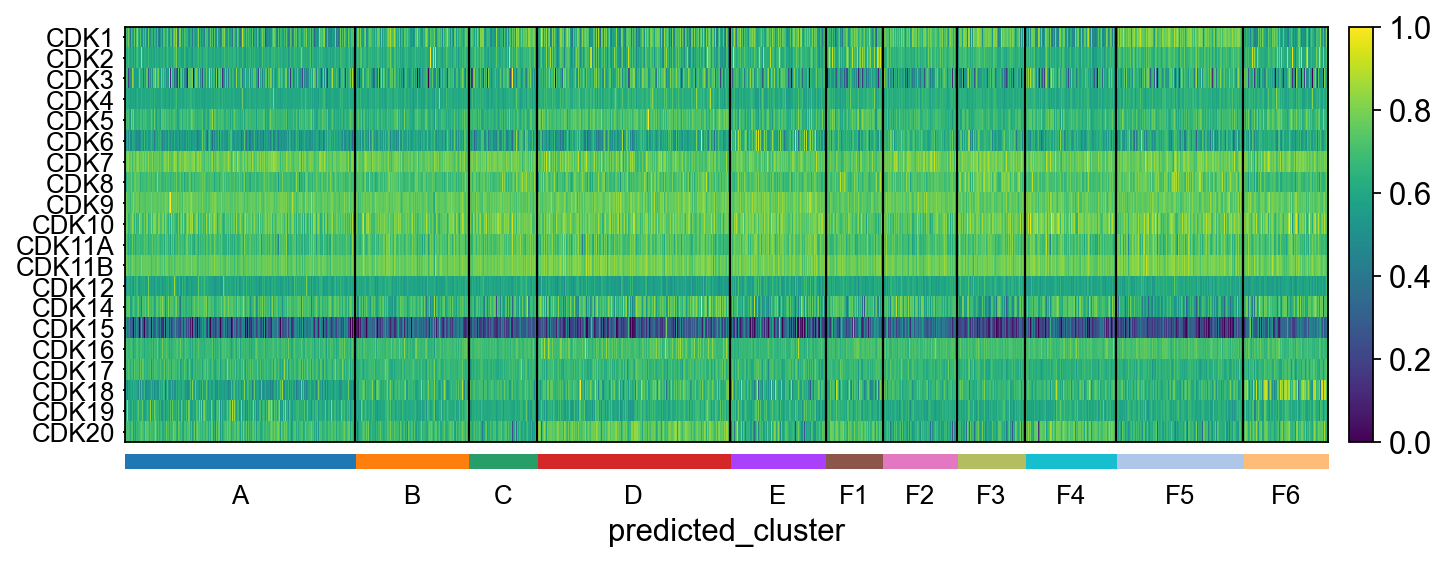

In [116]:
sc.pl.heatmap(adata, cdks, groupby='predicted_cluster', swap_axes=True, dendrogram=False, save= 'heatmap.png', standard_scale='var') #save= 'heatmap.png'

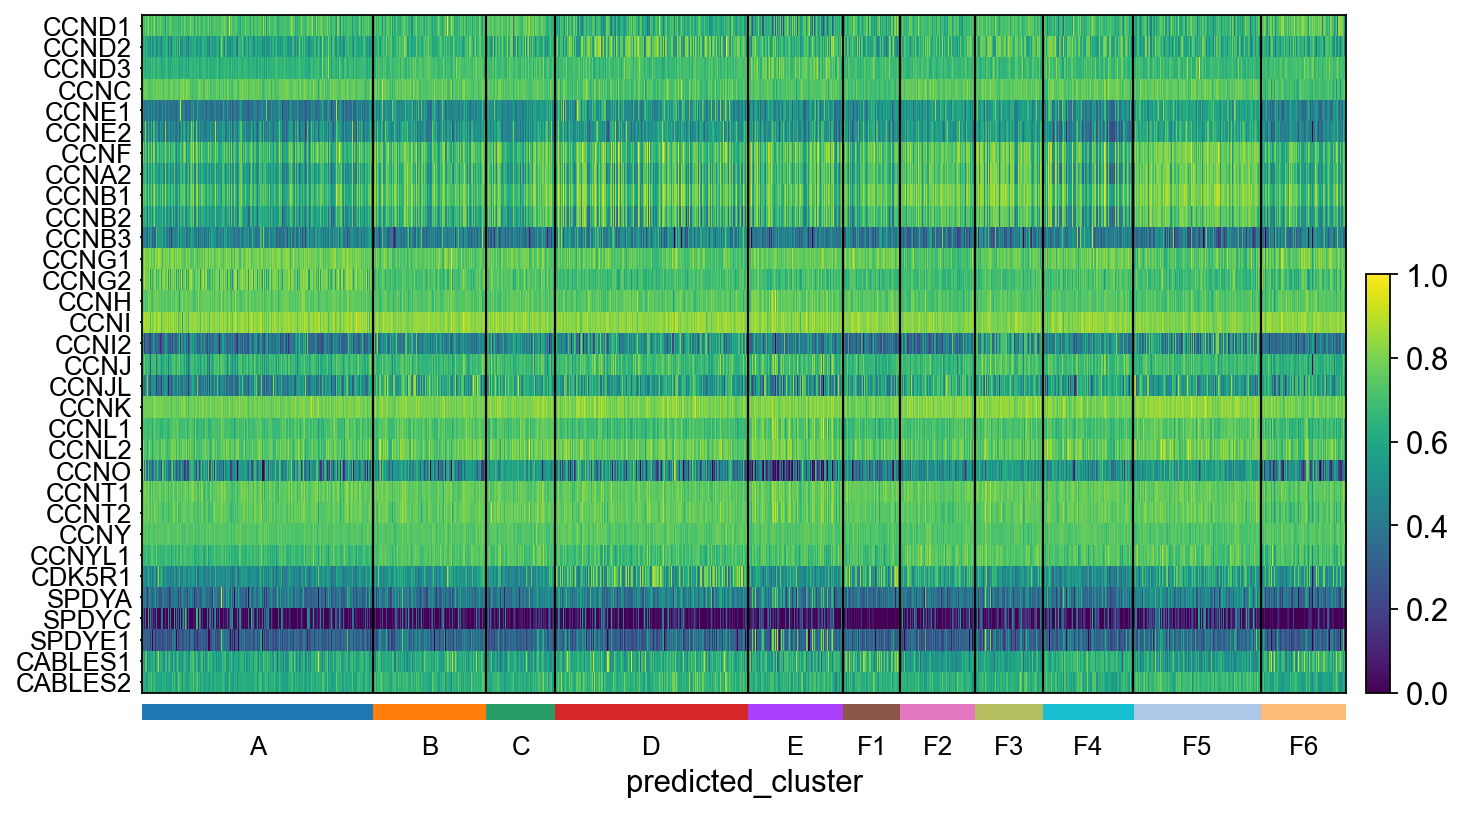

In [117]:
sc.pl.heatmap(adata, cyclins, groupby='predicted_cluster', swap_axes=True, dendrogram=False, save= 'heatmap.png', standard_scale='var') #save= 'heatmap.png'

# 3.2 BRCA

## SUBPOPULATION OF BRCA

In [84]:
adata.obs

,Patient_ID,Project_ID,age_at_initial_pathologic_diagnosis,gender,race,ajcc_pathologic_tumor_stage,clinical_stage,histological_type,histological_grade,initial_pathologic_dx_year,...,B,C,D,E,F1,F2,F3,F4,F5,F6
Sample_ID,,,,,,,,,,,,,,,,,,,,,
TCGA-S9-A7J2-01,TCGA-S9-A7J2,LGG,25.0,MALE,WHITE,nan,nan,Oligodendroglioma,G3,2013.0,...,-1.276433,-1.855283,2.189873,-1.040316,0.589348,-1.774074,-1.921665,0.088749,-1.977169,-1.179843
TCGA-G3-A3CH-11,TCGA-G3-A3CH,LIHC,53.0,MALE,ASIAN,Stage IIIA,nan,Hepatocellular Carcinoma,G2,2010.0,...,0.266875,-0.824769,-1.568131,0.432022,-1.580239,-1.181712,-0.767473,-0.930187,-0.486416,-0.547027
TCGA-EK-A2RE-01,TCGA-EK-A2RE,CESC,26.0,FEMALE,WHITE,nan,Stage IIA,Cervical Squamous Cell Carcinoma,G2,2010.0,...,-1.390549,1.381259,-0.084029,-1.817252,-0.306789,1.364495,1.476767,-0.938312,1.639155,0.472526
TCGA-44-6778-01,TCGA-44-6778,LUAD,59.0,MALE,BLACK OR AFRICAN AMERICAN,Stage IA,nan,Lung Adenocarcinoma,nan,2007.0,...,2.040552,-0.146154,1.368897,1.748241,0.808870,0.271267,-0.089814,0.738116,0.049822,-0.041854
TCGA-F4-6854-01,TCGA-F4-6854,COAD,77.0,FEMALE,WHITE,Stage IIA,nan,Colon Adenocarcinoma,nan,2011.0,...,-0.204253,0.334155,-0.612664,-0.356822,-0.159608,-0.208770,0.672233,0.064502,0.682047,-0.418509
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-VQ-AA6F-01,TCGA-VQ-AA6F,STAD,57.0,MALE,WHITE,Stage IIB,nan,"Stomach, Intestinal Adenocarcinoma, Not Otherw...",G2,2010.0,...,1.352542,1.578997,-0.464437,0.990900,-0.140035,0.036048,1.354195,0.866756,1.052047,0.394733
TCGA-BR-8588-01,TCGA-BR-8588,STAD,55.0,FEMALE,WHITE,Stage IIB,nan,"Stomach, Adenocarcinoma, Not Otherwise Specifi...",G3,2012.0,...,0.892088,0.685532,-0.269293,0.891402,0.324033,0.350763,0.677155,0.421968,0.736923,0.190966
TCGA-24-2254-01,TCGA-24-2254,OV,66.0,FEMALE,WHITE,nan,Stage IIIC,Serous Cystadenocarcinoma,G3,2003.0,...,-0.268725,0.337040,1.778820,-0.106366,0.822227,0.441183,0.470338,1.318080,0.520426,0.802791


In [118]:
ad_BRCA = adata[adata.obs.Project_ID == "BRCA"]
ad_BRCA_an = ad_BRCA[ad_BRCA.obs.Aneu != "nan"]

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:00)
computing PCA
Note that scikit-learn's randomized PCA might not be exactly reproducible across different computational platforms. For exact reproducibility, choose `svd_solver='arpack'.`
    on highly variable genes
    with n_comps=50
    finished (0:00:00)


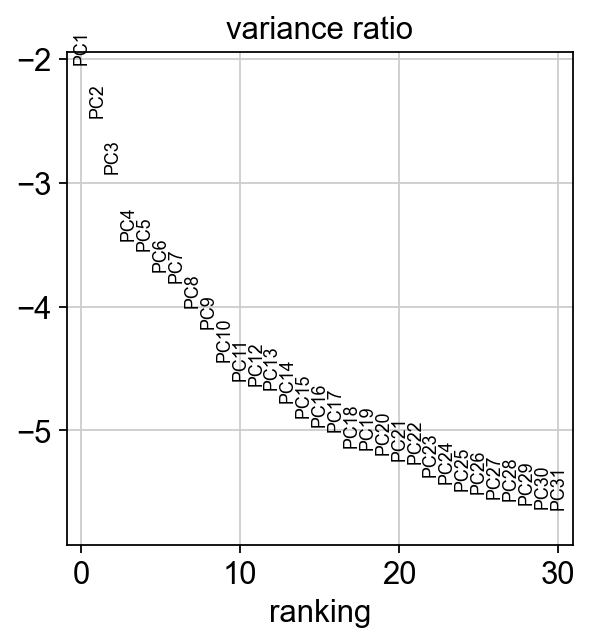

In [119]:
### reumap

sc.pp.pca(ad_BRCA)
sc.tl.pca(ad_BRCA, svd_solver='auto') 
sc.pl.pca_variance_ratio(ad_BRCA, log=True) 

In [120]:
sc.pp.neighbors(ad_BRCA, n_neighbors=12, n_pcs=40)
sc.tl.umap(ad_BRCA)

computing neighbors
    using 'X_pca' with n_pcs = 40
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:02)


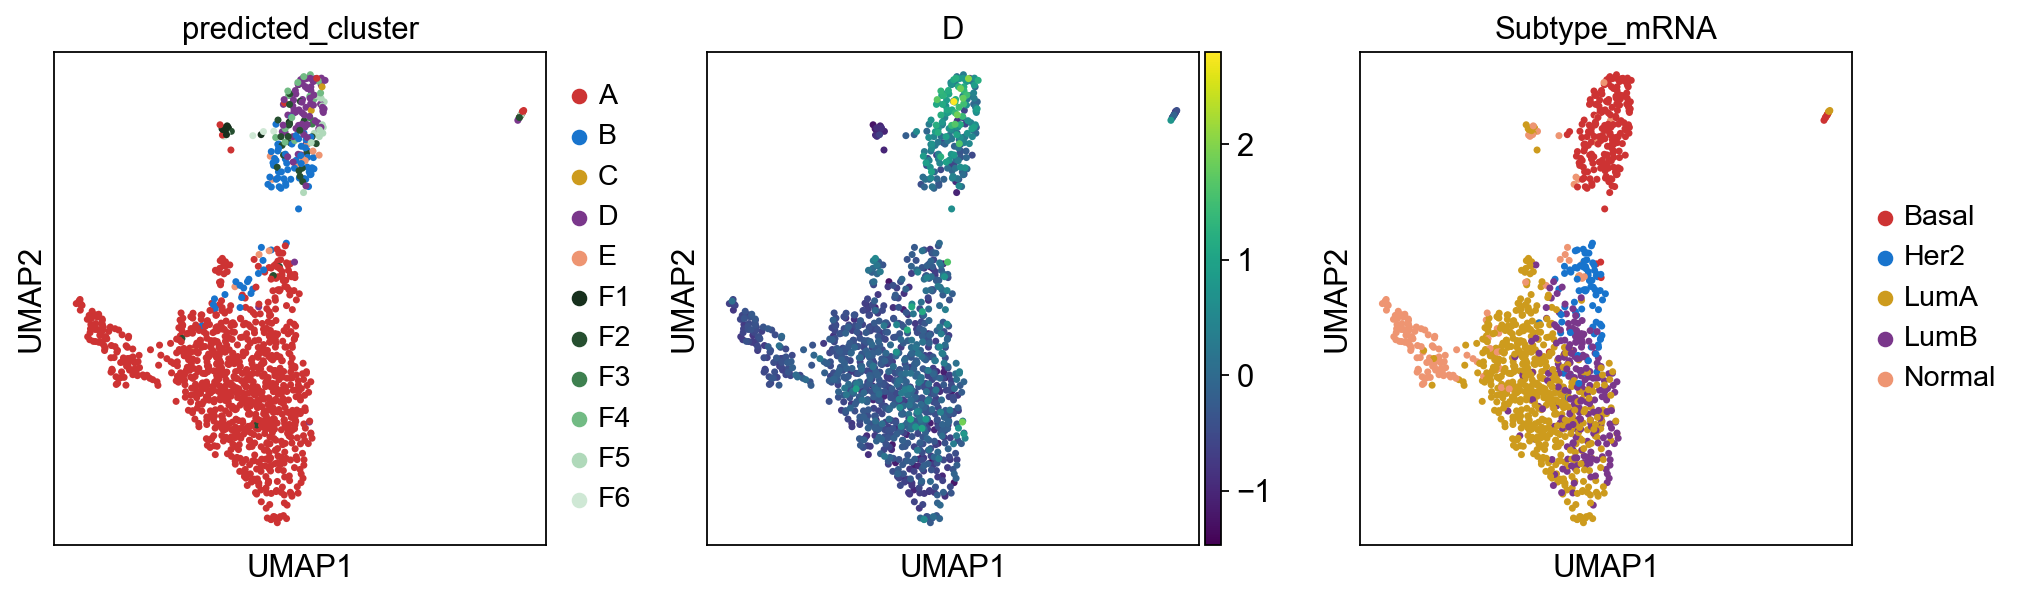

In [121]:
# --- 1️⃣ Asegurarse de que predicted_cluster sea tipo categorical ---
cluster_order = list(cluster_colors.keys())
ad_BRCA.obs['predicted_cluster'] = pd.Categorical(
    ad_BRCA.obs['predicted_cluster'],
    categories=cluster_order,
    ordered=True
)

# --- 2️⃣ Crear paleta en el mismo orden de las categorías ---
palette = [cluster_colors[c] for c in ad_BRCA.obs['predicted_cluster'].cat.categories]

# --- 3️⃣ UMAP con colores personalizados ---
sc.pl.umap(
    ad_BRCA,
    color=['predicted_cluster','D','Subtype_mRNA'],  # columnas a visualizar
    s=40,
    palette=palette,
    save=True
)

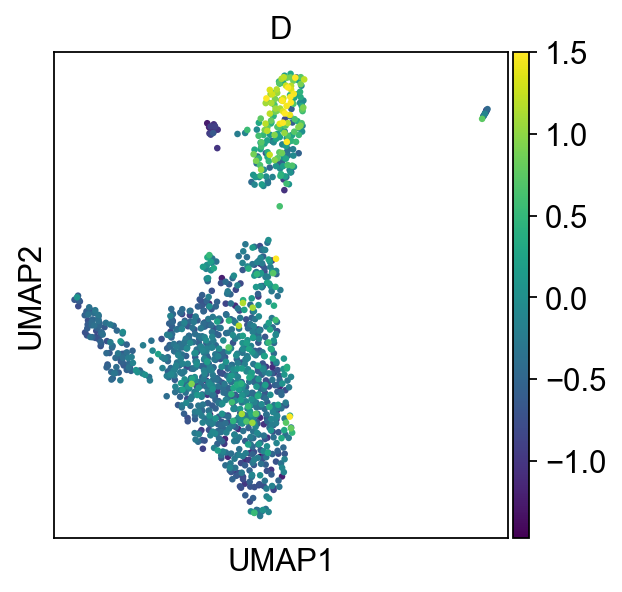

In [122]:
import scanpy as sc

# UMAP coloreado por score D, límite máximo en 2
sc.pl.umap(
    ad_BRCA,
    color='D',       # columna numérica
    s=35,
    cmap='viridis',  # colormap continuo
    #vmin=adata.obs['D'].min(),  # mínimo real de D
    vmax=1.5,                     # máximo fijo en 2
    save='_D_score_capped2.png'
)

In [136]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import os

# Genes de interés
genes = ['CCND1', 'CCND2','CCND3','CCNE1','CCNE2',
         'CDK2','CDK4','CDK6','CDK8','CCNC','CCNL1']

# Definir colores por cluster
cluster_colors = {
    "A"  : "#CD3333",
    "B"  : "#1874CD",
    "C"  : "#CD9B1D",
    "D"  : "#7A378B",
    "E"  : "#EE9572",
    "F1" : "#17301D",
    "F2" : "#264F30",
    "F3" : "#3E804F",
    "F4" : "#72BB84",
    "F5" : "#B0D9BA",
    "F6" : "#CFE8D5"
}

# Crear carpeta para guardar figuras
output_dir = "/Users/asanchezb/Desktop/boxplots_genes"
os.makedirs(output_dir, exist_ok=True)

# Extraer datos
data = adata[:, genes].X.toarray()
metadata = adata.obs['predicted_cluster']

df = pd.DataFrame(data, columns=genes)
df['predicted_cluster'] = metadata.values

# Forzar orden exacto de clusters según diccionario
cluster_order = list(cluster_colors.keys())
df['predicted_cluster'] = pd.Categorical(
    df['predicted_cluster'],
    categories=cluster_order,
    ordered=True
)

# Loop automático
for gene in genes:
    
    plt.figure(figsize=(6,5))
    
    sns.boxplot(
        x='predicted_cluster',
        y=gene,
        data=df,
        order=cluster_order,
        palette=cluster_colors
    )
    
    plt.title(f"{gene} expression by predicted_cluster")
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    # Guardar imagen
    plt.savefig(f"{output_dir}/{gene}_boxplot.png", dpi=300)
    plt.close()

print("Todos los boxplots fueron guardados correctamente.")



Todos los boxplots fueron guardados correctamente.


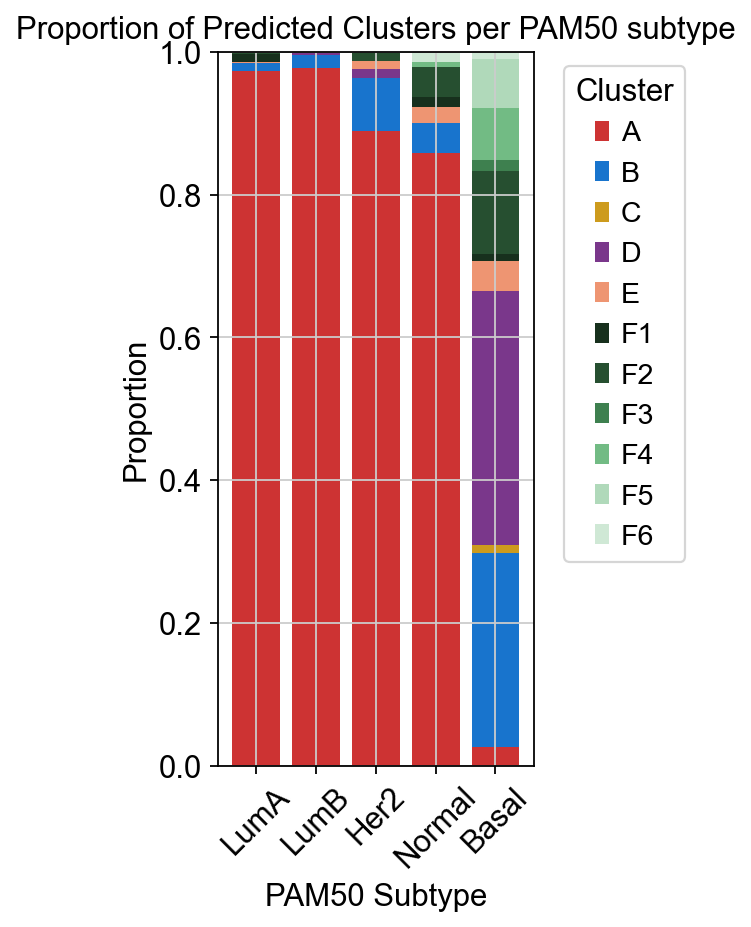

In [129]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Tabla de proporciones ---
prop_table = (
    ad_BRCA.obs
    .groupby(['Subtype_mRNA', 'predicted_cluster'])
    .size()
    .unstack(fill_value=0)
)

# Convertir a proporción por fila
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

# Colores de clusters
cluster_colors = {
    "A"  : "#CD3333",
    "B"  : "#1874CD",
    "C"  : "#CD9B1D",
    "D"  : "#7A378B",
    "E"  : "#EE9572",
    "F1" : "#17301D",
    "F2" : "#264F30",
    "F3" : "#3E804F",
    "F4" : "#72BB84",
    "F5" : "#B0D9BA",
    "F6" : "#CFE8D5"
}

# Asegurar orden de clusters en columnas
prop_table = prop_table[cluster_colors.keys()]

# --- 🔹 Reordenar filas por PAM50 ---
subtype_order = ['LumA', 'LumB', 'Her2', 'Normal', 'Basal']
prop_table = prop_table.reindex(subtype_order)

# --- Graficar stacked bar ---
fig, ax = plt.subplots(figsize=(4,6))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for cluster in prop_table.columns:
    ax.bar(
        x,
        prop_table[cluster],
        bottom=bottom,
        color=cluster_colors[cluster],
        label=cluster
    )
    bottom += prop_table[cluster].values

# --- Etiquetas ---
ax.set_xticks(x)
ax.set_xticklabels(prop_table.index, rotation=45)
ax.set_ylabel("Proportion")
ax.set_xlabel("PAM50 Subtype")
ax.set_title("Proportion of Predicted Clusters per PAM50 subtype")
ax.legend(title="Cluster", bbox_to_anchor=(1.05,1), loc="upper left", ncol=1)

plt.tight_layout()
plt.savefig("/Users/asanchezb/Desktop/stacked_bar_project_per_cluster.png", dpi=300) 
plt.show()

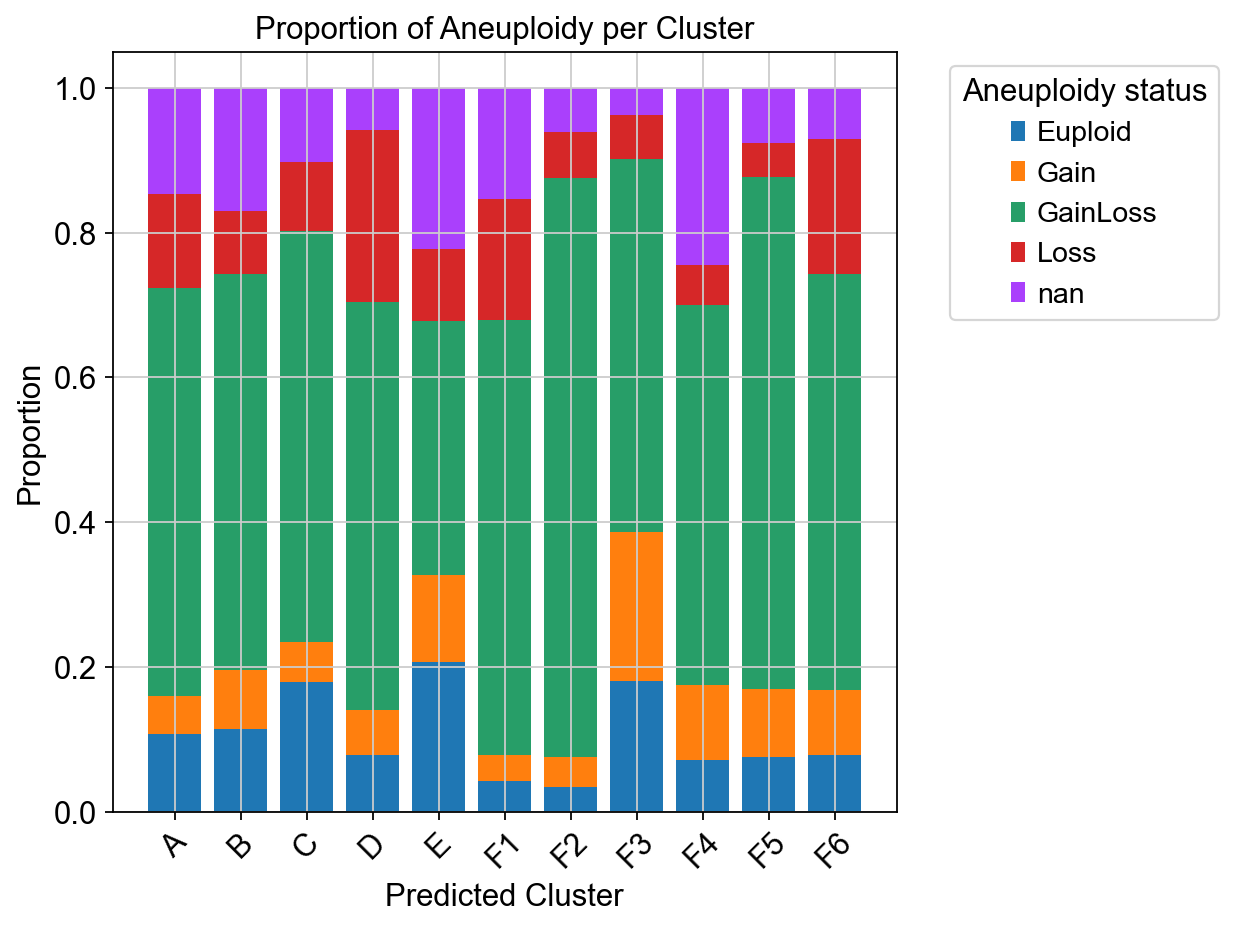

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Tabla de conteos
prop_table = (
    adata.obs
    .groupby(['predicted_cluster', 'Aneu'])
    .size()
    .unstack(fill_value=0)
)

# Convertir a proporciones por cluster
prop_table = prop_table.div(prop_table.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8,6))

bottom = np.zeros(len(prop_table))
x = np.arange(len(prop_table))

for status in prop_table.columns:
    ax.bar(x, prop_table[status], bottom=bottom, label=status)
    bottom += prop_table[status].values

ax.set_xticks(x)
ax.set_xticklabels(prop_table.index, rotation=45)
ax.set_ylabel("Proportion")
ax.set_xlabel("Predicted Cluster")
ax.set_title("Proportion of Aneuploidy per Cluster")
ax.legend(title="Aneuploidy status", bbox_to_anchor=(1.05,1), loc="upper left")


plt.tight_layout()
plt.show()

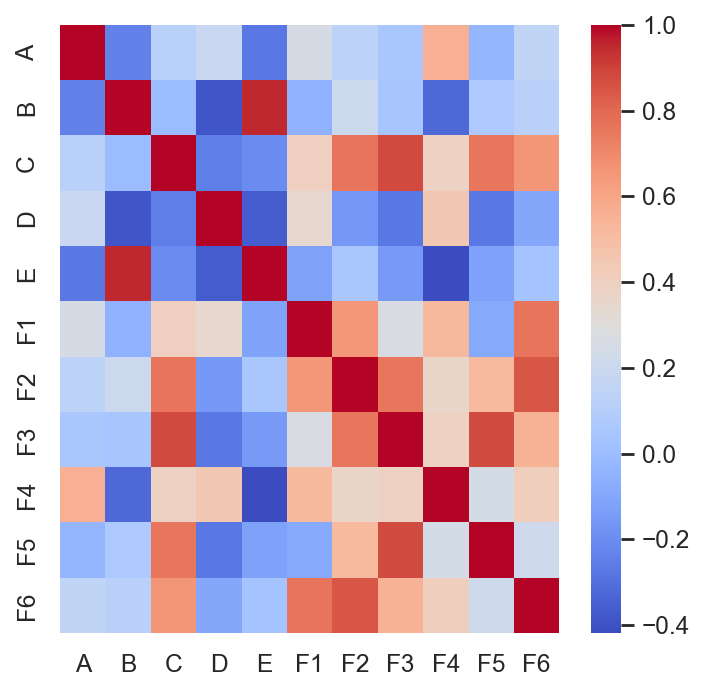

In [133]:
sns.set(font_scale=1)
fig, ax = plt.subplots(figsize=(5, 5))
ax = sns.heatmap(adata.obs[variables].corr(method='pearson'), 
            cmap=plt.get_cmap('coolwarm'), cbar=True, ax=ax)
#ax.set_yticklabels(ax.get_yticklabels(), rotation="horizontal")
#plt.savefig(PATH +'result.png', bbox_inches='tight', pad_inches=0.0)